# Modelo de Predicción PM10/PM2.5 — XGBoost — Protocolo de Tesis

Este notebook fue reorganizado para aplicar un **protocolo experimental homogéneo** entre Random Forest, XGBoost y MLP, adecuado para comparación en una tesis de maestría.

### Protocolo
- Particiones temporales: **60/40, 70/30, 80/20 y 90/10**, todas con pronóstico a **1 día**.
- Horizontes directos: **7, 30 y 90 días**, evaluados con una partición fija **80/20**.
- El objetivo es siempre futuro: `X(t) -> y(t+h)`.
- Separación cronológica, sin mezcla aleatoria.
- **Purga temporal** entre entrenamiento y prueba igual al horizonte `h`, para evitar que etiquetas futuras del entrenamiento invadan el periodo de prueba.
- Selección de hiperparámetros usando únicamente entrenamiento y validación temporal.
- Criterio principal de selección: **RMSE medio de validación**; desempate por MAE y menor desfase temporal.
- La predicción **no se desplaza artificialmente**. El desfase se diagnostica y se reporta.
- Comparación frente a un modelo base de **persistencia**.
- Exportación de métricas, predicciones, residuales, tiempos, hiperparámetros y validación.
- Para cada escenario se genera una figura de dos paneles:
  1. serie real de entrenamiento + serie real de prueba + predicción;
  2. residual `Real - Predicción` sobre el tramo de prueba.

> Nota: si las bases de entrada ya fueron imputadas previamente, este notebook no puede reconstruir qué valores eran originalmente observados a menos que exista una columna indicadora. Por ello, las métricas deben interpretarse de acuerdo con la naturaleza de la base suministrada.


In [1]:

# ============================================================
# 1. IMPORTACIONES Y CRONOMETRAJE GENERAL
# ============================================================
import os
import re
import json
import time
import warnings
from pathlib import Path
from functools import reduce
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

try:
    from statsmodels.stats.diagnostic import acorr_ljungbox
    STATSMODELS_OK = True
except Exception:
    STATSMODELS_OK = False

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 250)
pd.set_option("display.width", 200)

SEED = 42
np.random.seed(SEED)

TIEMPO_INICIO_NOTEBOOK = time.perf_counter()
FECHA_HORA_INICIO_NOTEBOOK = datetime.now()

print("Inicio:", FECHA_HORA_INICIO_NOTEBOOK.strftime("%Y-%m-%d %H:%M:%S"))


Inicio: 2026-08-13 23:11:39


In [2]:

# ============================================================
# 2. CONFIGURACIÓN EXPERIMENTAL COMÚN
# ============================================================
BASE_DIR = Path(".")
MOSTRAR_GRAFICAS = True

PARTICIONES = [
    {"Tipo_evaluacion": "Porcentaje", "Escenario": "60_40", "Entrenamiento_%": 60, "Prediccion_%": 40, "train_frac": 0.60, "Horizonte_dias": 1},
    {"Tipo_evaluacion": "Porcentaje", "Escenario": "70_30", "Entrenamiento_%": 70, "Prediccion_%": 30, "train_frac": 0.70, "Horizonte_dias": 1},
    {"Tipo_evaluacion": "Porcentaje", "Escenario": "80_20", "Entrenamiento_%": 80, "Prediccion_%": 20, "train_frac": 0.80, "Horizonte_dias": 1},
    {"Tipo_evaluacion": "Porcentaje", "Escenario": "90_10", "Entrenamiento_%": 90, "Prediccion_%": 10, "train_frac": 0.90, "Horizonte_dias": 1},
]

HORIZONTES = [
    {"Tipo_evaluacion": "Horizonte", "Escenario": "H_7_dias",  "Entrenamiento_%": 80, "Prediccion_%": 20, "train_frac": 0.80, "Horizonte_dias": 7},
    {"Tipo_evaluacion": "Horizonte", "Escenario": "H_30_dias", "Entrenamiento_%": 80, "Prediccion_%": 20, "train_frac": 0.80, "Horizonte_dias": 30},
    {"Tipo_evaluacion": "Horizonte", "Escenario": "H_90_dias", "Entrenamiento_%": 80, "Prediccion_%": 20, "train_frac": 0.80, "Horizonte_dias": 90},
]

ESCENARIOS = PARTICIONES + HORIZONTES

TARGETS_CANDIDATOS = ["PM10", "PM25"]
COVARIABLES_BASE = ["HAire2", "TAire2", "VViento", "DViento"]

# Ingeniería de características común a los tres modelos.
REZAGOS_TARGET = [0, 1, 2, 3, 7, 14, 30]
VENTANAS_TARGET = [3, 7, 14, 30]
REZAGOS_OTRO_CONTAMINANTE = [0, 1, 7, 14]
REZAGOS_METEO = [0, 1, 7]

# Requisitos mínimos. Si H=90 no permite CV purgada, se usa configuración base,
# pero se deja explícito en la salida.
MIN_TRAIN_FINAL = 50
MIN_TRAIN_CV = 45
N_FOLDS_CV_DESEADOS = 4

display(Markdown("### Escenarios experimentales"))
display(pd.DataFrame(ESCENARIOS))


### Escenarios experimentales

,Tipo_evaluacion,Escenario,Entrenamiento_%,Prediccion_%,train_frac,Horizonte_dias
0,Porcentaje,60_40,60,40,0.6,1
1,Porcentaje,70_30,70,30,0.7,1
2,Porcentaje,80_20,80,20,0.8,1
3,Porcentaje,90_10,90,10,0.9,1
4,Horizonte,H_7_dias,80,20,0.8,7
5,Horizonte,H_30_dias,80,20,0.8,30
6,Horizonte,H_90_dias,80,20,0.8,90


In [3]:

# ============================================================
# 3. CARGA ROBUSTA E INTEGRACIÓN
# ============================================================
PATRONES = {
    "PM10": [
        "PM10_dataset_completo.csv", "PM10_DATASET_FINAL_IMPUTADO.csv",
        "PM10_dataset_final_imputado_RF_atipicos.csv", "*PM10*completo*.csv",
        "*PM10*FINAL*IMPUTADO*.csv", "*PM10*.csv", "*PM10*.xlsx"
    ],
    "PM25": [
        "PM2.5_dataset_completo.csv", "PM25_DATASET_FINAL_IMPUTADO.csv",
        "PM2.5_DATASET_FINAL_IMPUTADO.csv", "PM25_dataset_final_imputado_RF_atipicos.csv",
        "*PM2.5*completo*.csv", "*PM25*FINAL*IMPUTADO*.csv", "*PM2.5*.csv",
        "*PM25*.csv", "*PM2.5*.xlsx", "*PM25*.xlsx"
    ],
    "HAire2": [
        "HAire2_dataset_completo_final.csv", "HAire2_DATASET_FINAL_IMPUTADO.csv",
        "*HAire2*completo*.csv", "*HAire2*FINAL*IMPUTADO*.csv", "*HAire2*.csv", "*HAire2*.xlsx"
    ],
    "TAire2": [
        "TAire2_dataset_completo_final.csv", "TAire2_DATASET_FINAL_IMPUTADO.csv",
        "*TAire2*completo*.csv", "*TAire2*FINAL*IMPUTADO*.csv", "*TAire2*.csv", "*TAire2*.xlsx"
    ],
    "VViento": [
        "VViento_dataset_completo.xlsx", "VViento_DATASET_FINAL_IMPUTADO.csv",
        "*VViento*completo*.xlsx", "*VViento*FINAL*IMPUTADO*.csv", "*VViento*.csv", "*VViento*.xlsx"
    ],
    "DViento": [
        "DViento_dataset_completo_final.csv", "DViento_DATASET_FINAL_IMPUTADO.csv",
        "*DViento*completo*.csv", "*DViento*FINAL*IMPUTADO*.csv", "*DViento*.csv", "*DViento*.xlsx"
    ],
}

def _limpiar_col(c):
    return str(c).replace("\ufeff", "").strip()

def _norm(txt):
    txt = _limpiar_col(txt).lower()
    for a, b in {"á":"a","é":"e","í":"i","ó":"o","ú":"u","ñ":"n"}.items():
        txt = txt.replace(a, b)
    return re.sub(r"\s+", " ", txt)

def buscar_archivo(patrones):
    vistos = set()
    for patron in patrones:
        for ruta in sorted(BASE_DIR.glob(patron)):
            s = str(ruta)
            if s not in vistos:
                vistos.add(s)
                return ruta
    return None

def load_table(path):
    if path is None:
        raise FileNotFoundError("No se detectó el archivo requerido.")
    path = Path(path)
    if path.suffix.lower() == ".csv":
        try:
            df = pd.read_csv(path, encoding="utf-8")
        except UnicodeDecodeError:
            df = pd.read_csv(path, encoding="latin1")
    elif path.suffix.lower() in [".xlsx", ".xls"]:
        xls = pd.ExcelFile(path)
        hoja = "VViento_final" if "VViento_final" in xls.sheet_names else ("DATASET_FINAL" if "DATASET_FINAL" in xls.sheet_names else xls.sheet_names[0])
        df = pd.read_excel(path, sheet_name=hoja)
    else:
        raise ValueError(f"Formato no soportado: {path}")
    df.columns = [_limpiar_col(c) for c in df.columns]
    return df

def encontrar_columna(df, alias):
    mapa = {_norm(c): c for c in df.columns}
    for a in alias:
        if _norm(a) in mapa:
            return mapa[_norm(a)]
    for c in df.columns:
        cn = _norm(c)
        for a in alias:
            an = _norm(a)
            if an in cn or cn in an:
                return c
    return None

def standardize_base(df, variable, nombre_final=None):
    nombre_final = nombre_final or variable
    col_est = encontrar_columna(df, ["Estacion", "Estación", "Nombre estacion", "Nombre de estación", "station", "site"])
    col_fecha = encontrar_columna(df, ["Fecha inicial", "Fecha", "date", "Fecha Inicial"])
    alias_var = [variable]
    if variable in ["PM25", "PM2.5"]:
        alias_var += ["PM25", "PM2.5", "PM 2.5", "PM_2_5", "PM2_5"]
    col_var = encontrar_columna(df, alias_var)
    if col_est is None or col_fecha is None or col_var is None:
        raise ValueError(f"No se identificaron Estacion/Fecha/{variable}. Columnas: {df.columns.tolist()}")
    out = df[[col_est, col_fecha, col_var]].copy()
    out.columns = ["Estacion", "Fecha inicial", nombre_final]
    out["Estacion"] = out["Estacion"].astype(str).str.strip().str.upper()
    out["Fecha inicial"] = pd.to_datetime(out["Fecha inicial"], errors="coerce")
    out[nombre_final] = pd.to_numeric(out[nombre_final], errors="coerce")
    out = out.dropna(subset=["Estacion", "Fecha inicial"])
    # Si existen duplicados estación-fecha, se consolida por promedio.
    out = out.groupby(["Estacion", "Fecha inicial"], as_index=False)[nombre_final].mean()
    return out

rutas = {k: buscar_archivo(v) for k, v in PATRONES.items()}
display(pd.DataFrame([{"Variable": k, "Archivo_detectado": str(v) if v else None, "Existe": bool(v and v.exists())} for k, v in rutas.items()]))

faltantes_archivos = [k for k, v in rutas.items() if v is None]
if faltantes_archivos:
    raise FileNotFoundError(
        "Faltan archivos para: " + ", ".join(faltantes_archivos) +
        ". Ajusta BASE_DIR o los patrones en la celda de carga."
    )

bases = [
    standardize_base(load_table(rutas["PM10"]), "PM10"),
    standardize_base(load_table(rutas["PM25"]), "PM2.5", "PM25"),
    standardize_base(load_table(rutas["HAire2"]), "HAire2"),
    standardize_base(load_table(rutas["TAire2"]), "TAire2"),
    standardize_base(load_table(rutas["VViento"]), "VViento"),
    standardize_base(load_table(rutas["DViento"]), "DViento"),
]

df_master = reduce(
    lambda left, right: pd.merge(left, right, on=["Estacion", "Fecha inicial"], how="outer"),
    bases
).sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

TARGETS = [t for t in TARGETS_CANDIDATOS if t in df_master.columns]
ESTACIONES = sorted(df_master["Estacion"].dropna().unique())

display(Markdown("### Resumen de la base integrada"))
display(pd.DataFrame([{
    "Registros": len(df_master),
    "Estaciones": len(ESTACIONES),
    "Fecha_min": df_master["Fecha inicial"].min(),
    "Fecha_max": df_master["Fecha inicial"].max(),
    "Targets": str(TARGETS)
}]))
display(df_master.groupby("Estacion").size().reset_index(name="N_registros"))
display(df_master.isna().sum().reset_index().rename(columns={"index":"Variable", 0:"N_nulos"}))


,Variable,Archivo_detectado,Existe
0,PM10,PM10_DATASET_FINAL_IMPUTADO.csv,True
1,PM25,PM25_DATASET_FINAL_IMPUTADO.csv,True
2,HAire2,HAire2_dataset_completo_final.csv,True
3,TAire2,TAire2_dataset_completo_final.csv,True
4,VViento,VViento_dataset_completo_final.csv,True
5,DViento,DViento_dataset_completo_final.csv,True


### Resumen de la base integrada

,Registros,Estaciones,Fecha_min,Fecha_max,Targets
0,1462,2,2020-01-01,2021-12-31,"['PM10', 'PM25']"


,Estacion,N_registros
0,CENTRO DE ALTO RENDIMIENTO,731
1,KENNEDY,731


,Variable,N_nulos
0,Estacion,0
1,Fecha inicial,0
2,PM10,0
3,PM25,0
4,HAire2,0
5,TAire2,0
6,VViento,0
7,DViento,0


## Ingeniería de características

Se usa exactamente la misma definición de variables en los tres modelos para mantener una comparación justa.

In [4]:

# ============================================================
# 4. INGENIERÍA DE CARACTERÍSTICAS SIN INFORMACIÓN FUTURA
# ============================================================
def preparar_features_estacion(df_master, estacion, target, horizonte):
    """
    Construye X(t) -> y(t+h).
    No usa interpolación bidireccional ni bfill dentro del modelado.
    Las filas con información insuficiente se eliminan.
    """
    d = df_master[df_master["Estacion"] == estacion].copy()
    d = d.sort_values("Fecha inicial").set_index("Fecha inicial").asfreq("D")

    for c in ["PM10", "PM25", "HAire2", "TAire2", "VViento", "DViento"]:
        if c in d.columns:
            d[c] = pd.to_numeric(d[c], errors="coerce")

    # Variables calendario en la fecha origen t.
    d["doy_sin"] = np.sin(2 * np.pi * d.index.dayofyear / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * d.index.dayofyear / 365.25)
    d["dow_sin"] = np.sin(2 * np.pi * d.index.dayofweek / 7)
    d["dow_cos"] = np.cos(2 * np.pi * d.index.dayofweek / 7)

    if "DViento" in d.columns:
        d["DViento_sin"] = np.sin(np.deg2rad(d["DViento"]))
        d["DViento_cos"] = np.cos(np.deg2rad(d["DViento"]))

    features = []

    # Target conocido en t y rezagos.
    for lag in REZAGOS_TARGET:
        nombre = f"{target}_lag_{lag}"
        d[nombre] = d[target].shift(lag)
        features.append(nombre)

    # Estadísticos históricos. Se usa shift(1): no incluye el valor del día actual.
    hist = d[target].shift(1)
    for w in VENTANAS_TARGET:
        d[f"{target}_roll_mean_{w}"] = hist.rolling(w).mean()
        d[f"{target}_roll_std_{w}"] = hist.rolling(w).std()
        features += [f"{target}_roll_mean_{w}", f"{target}_roll_std_{w}"]

    d[f"{target}_diff_1"] = d[target] - d[target].shift(1)
    d[f"{target}_diff_7"] = d[target] - d[target].shift(7)
    features += [f"{target}_diff_1", f"{target}_diff_7"]

    # Otro contaminante, si está disponible.
    otro = "PM25" if target == "PM10" else "PM10"
    if otro in d.columns:
        for lag in REZAGOS_OTRO_CONTAMINANTE:
            nombre = f"{otro}_lag_{lag}"
            d[nombre] = d[otro].shift(lag)
            features.append(nombre)

    # Meteorología disponible en la fecha origen y sus rezagos pasados.
    for cov in ["HAire2", "TAire2", "VViento"]:
        if cov in d.columns:
            for lag in REZAGOS_METEO:
                nombre = f"{cov}_lag_{lag}"
                d[nombre] = d[cov].shift(lag)
                features.append(nombre)

    for cov in ["DViento_sin", "DViento_cos"]:
        if cov in d.columns:
            for lag in REZAGOS_METEO:
                nombre = f"{cov}_lag_{lag}"
                d[nombre] = d[cov].shift(lag)
                features.append(nombre)

    features += ["doy_sin", "doy_cos", "dow_sin", "dow_cos"]

    # Objetivo directo futuro y fecha objetivo.
    d["y"] = d[target].shift(-horizonte)
    d["Fecha_objetivo"] = pd.Series(d.index, index=d.index).shift(-horizonte)
    d["Persistencia"] = d[target]

    columnas = features + ["y", "Persistencia", "Fecha_objetivo"]
    data = d[columnas].replace([np.inf, -np.inf], np.nan).dropna().copy()

    # Elimina columnas constantes para evitar ruido.
    features = [c for c in features if c in data.columns and data[c].nunique(dropna=True) > 1]
    data = data[features + ["y", "Persistencia", "Fecha_objetivo"]]

    return data, features


In [5]:

# ============================================================
# 5. MÉTRICAS, DESFASE Y DIAGNÓSTICO RESIDUAL
# ============================================================
def calcular_metricas(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_real) & np.isfinite(y_pred)
    y_real, y_pred = y_real[mask], y_pred[mask]
    if len(y_real) == 0:
        return {k: np.nan for k in ["MAE","RMSE","MAPE_%","sMAPE_%","WAPE_%","R2","Sesgo"]}

    err = y_real - y_pred
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred) if len(y_real) > 1 else np.nan

    nz = np.abs(y_real) > 1e-9
    mape = np.mean(np.abs(err[nz] / y_real[nz])) * 100 if nz.any() else np.nan
    smape = np.mean(2 * np.abs(err) / (np.abs(y_real) + np.abs(y_pred) + 1e-9)) * 100
    wape = np.sum(np.abs(err)) / (np.sum(np.abs(y_real)) + 1e-9) * 100
    sesgo = np.mean(err)

    return {"MAE":mae, "RMSE":rmse, "MAPE_%":mape, "sMAPE_%":smape, "WAPE_%":wape, "R2":r2, "Sesgo":sesgo}

def diagnostico_desfase(y_real, y_pred, max_lag=14):
    """
    Diagnóstico, no corrección. Busca el lag con mayor correlación.
    La predicción original nunca se desplaza para calcular las métricas.
    """
    real = pd.Series(np.asarray(y_real, dtype=float)).reset_index(drop=True)
    pred = pd.Series(np.asarray(y_pred, dtype=float)).reset_index(drop=True)
    max_lag = int(min(max_lag, max(1, len(real)//4)))

    corr0 = real.corr(pred)
    mejor_lag, mejor_corr = 0, corr0
    for lag in range(-max_lag, max_lag + 1):
        corr = real.corr(pred.shift(lag))
        if pd.notna(corr) and (pd.isna(mejor_corr) or corr > mejor_corr):
            mejor_lag, mejor_corr = lag, corr
    return {
        "Lag_optimo_dias": int(mejor_lag),
        "Lag_abs_dias": abs(int(mejor_lag)),
        "Correlacion_lag0": corr0,
        "Correlacion_max_desfase": mejor_corr
    }

def diagnostico_residuos(residuales):
    r = pd.Series(np.asarray(residuales, dtype=float)).replace([np.inf,-np.inf], np.nan).dropna()
    out = {"LjungBox_lag7_pvalue": np.nan, "LjungBox_lag14_pvalue": np.nan}
    if not STATSMODELS_OK or len(r) < 12:
        return out
    lags = [lag for lag in [7,14] if lag < len(r)-1]
    if not lags:
        return out
    try:
        lb = acorr_ljungbox(r, lags=lags, return_df=True)
        for lag in lags:
            out[f"LjungBox_lag{lag}_pvalue"] = float(lb.loc[lag, "lb_pvalue"])
    except Exception:
        pass
    return out

def crear_tscv_factible(n, gap, deseados=N_FOLDS_CV_DESEADOS):
    """
    Busca un TimeSeriesSplit factible conservando gap temporal.
    Devuelve None cuando la serie es demasiado corta; en ese caso no se
    seleccionan hiperparámetros mirando el test.
    """
    for n_splits in range(deseados, 1, -1):
        disponible = n - gap - MIN_TRAIN_CV
        test_size = min(30, disponible // n_splits) if disponible > 0 else 0
        if test_size < 5:
            continue
        try:
            tscv = TimeSeriesSplit(n_splits=n_splits, test_size=test_size, gap=gap)
            folds = list(tscv.split(np.arange(n)))
            if folds and min(len(tr) for tr, _ in folds) >= MIN_TRAIN_CV:
                return tscv, n_splits, test_size
        except Exception:
            continue
    return None, 0, 0

def plot_escenario(modelo_nombre, estacion, target, escenario, fechas_train, y_train, fechas_test, y_test, y_pred, out_path):
    residual = np.asarray(y_test) - np.asarray(y_pred)

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(15, 8), sharex=True,
        gridspec_kw={"height_ratios":[3,1]}
    )

    ax1.plot(fechas_train, y_train, label="Real entrenamiento", linewidth=1.2)
    ax1.plot(fechas_test, y_test, label="Real prueba", linewidth=1.5)
    ax1.plot(fechas_test, y_pred, label=f"Predicción prueba {modelo_nombre}", linewidth=1.5)
    ax1.axvline(pd.to_datetime(fechas_test).min(), linestyle="--", linewidth=1.1, label="Inicio prueba")
    ax1.set_title(f"{modelo_nombre} - {target.replace('PM25','PM2.5')} - {estacion} - {escenario}")
    ax1.set_ylabel(f"{target.replace('PM25','PM2.5')} (µg/m³)")
    ax1.grid(True, alpha=0.25)
    ax1.legend(ncol=2, fontsize=9)

    ax2.plot(fechas_test, residual, label="Residual = Real - Predicción", linewidth=1.1)
    ax2.axhline(0, linestyle="--", linewidth=1)
    ax2.set_xlabel("Fecha")
    ax2.set_ylabel("Residual")
    ax2.grid(True, alpha=0.25)
    ax2.legend(fontsize=9)

    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(out_path, dpi=170, bbox_inches="tight")
    if MOSTRAR_GRAFICAS:
        plt.show()
    plt.close(fig)


## Modelo y selección de hiperparámetros

In [6]:

# ============================================================
# 6. XGBOOST: HIPERPARÁMETROS Y VALIDACIÓN TEMPORAL
# ============================================================
try:
    from xgboost import XGBRegressor
except ImportError as e:
    raise ImportError(
        "XGBoost no está instalado. En tu entorno ejecuta: pip install xgboost"
    ) from e

MODELO_NOMBRE = "XGBoost"
MODELO_CORTO = "XGB"

OUT_DIR = Path("salidas_XGB_TESIS_PROTOCOLO_HOMOGENEO")
TABLAS_DIR = OUT_DIR / "tablas"
GRAF_DIR = OUT_DIR / "graficas"
TABLAS_DIR.mkdir(parents=True, exist_ok=True)
GRAF_DIR.mkdir(parents=True, exist_ok=True)

PARAM_GRID = [
    {"n_estimators": 300, "max_depth": 3, "learning_rate": 0.05, "subsample": 0.80, "colsample_bytree": 0.80, "min_child_weight": 1, "reg_lambda": 1.0},
    {"n_estimators": 500, "max_depth": 3, "learning_rate": 0.03, "subsample": 0.85, "colsample_bytree": 0.80, "min_child_weight": 1, "reg_lambda": 2.0},
    {"n_estimators": 500, "max_depth": 4, "learning_rate": 0.03, "subsample": 0.90, "colsample_bytree": 0.85, "min_child_weight": 2, "reg_lambda": 2.0},
    {"n_estimators": 700, "max_depth": 4, "learning_rate": 0.02, "subsample": 0.90, "colsample_bytree": 0.90, "min_child_weight": 2, "reg_lambda": 3.0},
]

def construir_modelo(params):
    return XGBRegressor(
        objective="reg:squarederror",
        tree_method="hist",
        random_state=SEED,
        n_jobs=-1,
        verbosity=0,
        **params
    )

def seleccionar_hiperparametros(X_train, y_train, horizonte):
    tscv, n_splits, test_size = crear_tscv_factible(len(X_train), gap=horizonte)

    if tscv is None:
        return PARAM_GRID[1].copy(), pd.DataFrame(), pd.DataFrame(), "Configuracion_base_CV_purgada_no_factible"

    detalle = []
    for cid, params in enumerate(PARAM_GRID):
        for fold, (itr, iva) in enumerate(tscv.split(X_train), start=1):
            model = construir_modelo(params)
            t0 = time.perf_counter()
            model.fit(X_train.iloc[itr], y_train.iloc[itr])
            pred = np.clip(model.predict(X_train.iloc[iva]), 0, None)
            tfit = time.perf_counter() - t0
            met = calcular_metricas(y_train.iloc[iva], pred)
            lag = diagnostico_desfase(y_train.iloc[iva], pred)
            detalle.append({
                "id_config": cid, "Fold": fold, "n_splits": n_splits, "test_size_cv": test_size,
                "RMSE": met["RMSE"], "MAE": met["MAE"], "R2": met["R2"],
                "Lag_abs_dias": lag["Lag_abs_dias"], "Lag_optimo_dias": lag["Lag_optimo_dias"],
                "Tiempo_fold_segundos": tfit, "Parametros": json.dumps(params, default=str)
            })

    detalle_df = pd.DataFrame(detalle)
    resumen = (
        detalle_df.groupby("id_config", as_index=False)
        .agg(
            RMSE_CV_media=("RMSE","mean"),
            RMSE_CV_std=("RMSE","std"),
            MAE_CV_media=("MAE","mean"),
            R2_CV_media=("R2","mean"),
            Lag_abs_CV_medio=("Lag_abs_dias","mean"),
            Tiempo_CV_candidato_segundos=("Tiempo_fold_segundos","sum")
        )
        .sort_values(["RMSE_CV_media","MAE_CV_media","Lag_abs_CV_medio"])
        .reset_index(drop=True)
    )
    resumen["Parametros"] = resumen["id_config"].apply(lambda i: json.dumps(PARAM_GRID[int(i)], default=str))
    mejor_id = int(resumen.iloc[0]["id_config"])
    return PARAM_GRID[mejor_id].copy(), resumen, detalle_df, "RMSE_CV_temporal_purgada"

def obtener_importancia(modelo, X_test, y_test, features):
    if not hasattr(modelo, "feature_importances_"):
        return pd.DataFrame()
    return pd.DataFrame({
        "Feature": features,
        "Importancia": modelo.feature_importances_
    }).sort_values("Importancia", ascending=False).reset_index(drop=True)

display(Markdown("### Configuraciones candidatas - XGBoost"))
display(pd.DataFrame(PARAM_GRID))


### Configuraciones candidatas - XGBoost

,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda
0,300,3,0.05,0.80,0.80,1,1.0
1,500,3,0.03,0.85,0.80,1,2.0
2,500,4,0.03,0.90,0.85,2,2.0
3,700,4,0.02,0.90,0.90,2,3.0


## Ejecución de los siete escenarios

Cada estación y contaminante se evalúa en los cuatro splits porcentuales y en los tres horizontes directos.


XGBoost | Estación=CENTRO DE ALTO RENDIMIENTO | Target=PM10


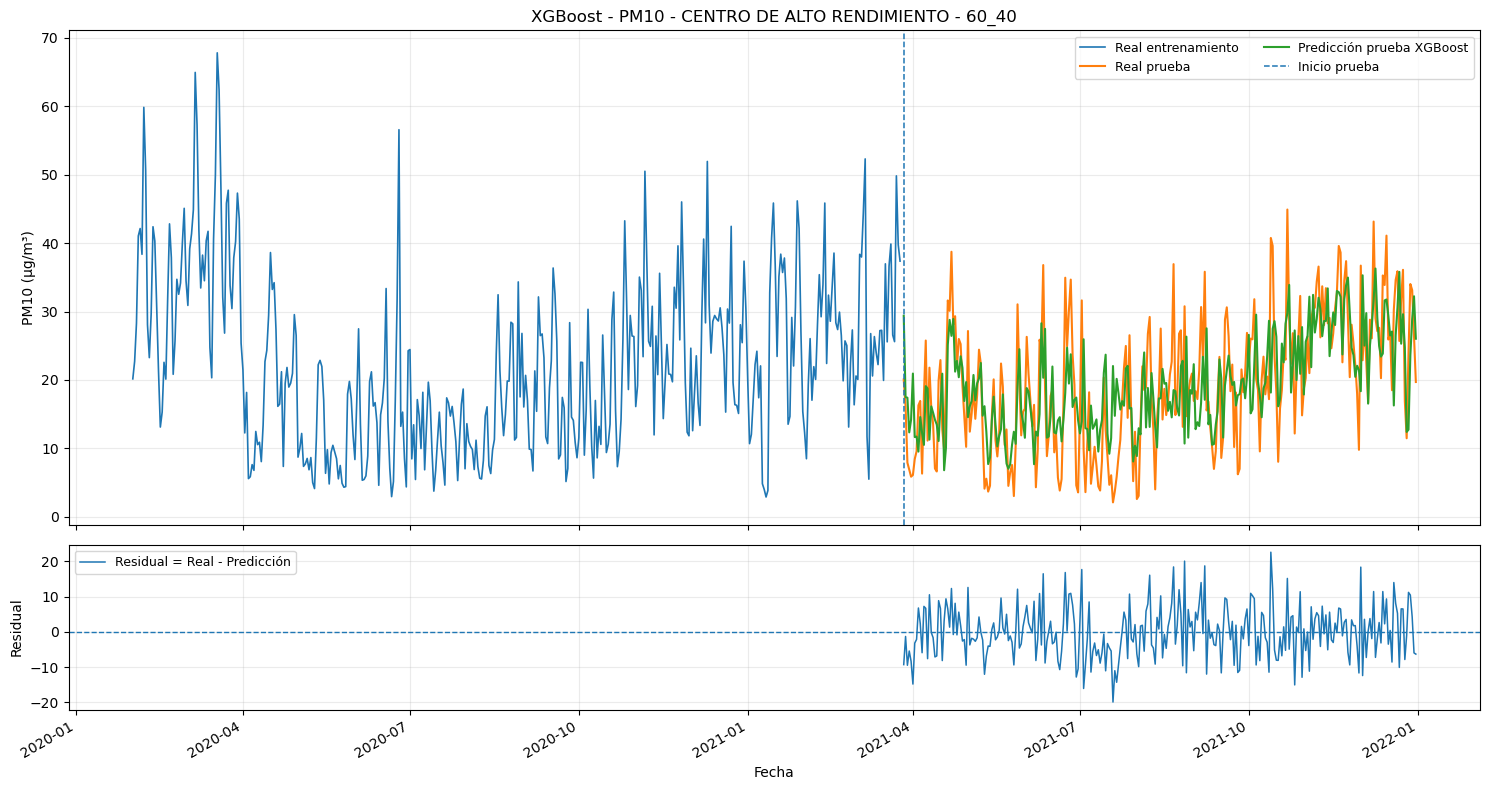

60_40 | H=1 | RMSE=7.4675 | R2=0.3884 | lag=-1 | tiempo=27.52s | RMSE_CV_temporal_purgada


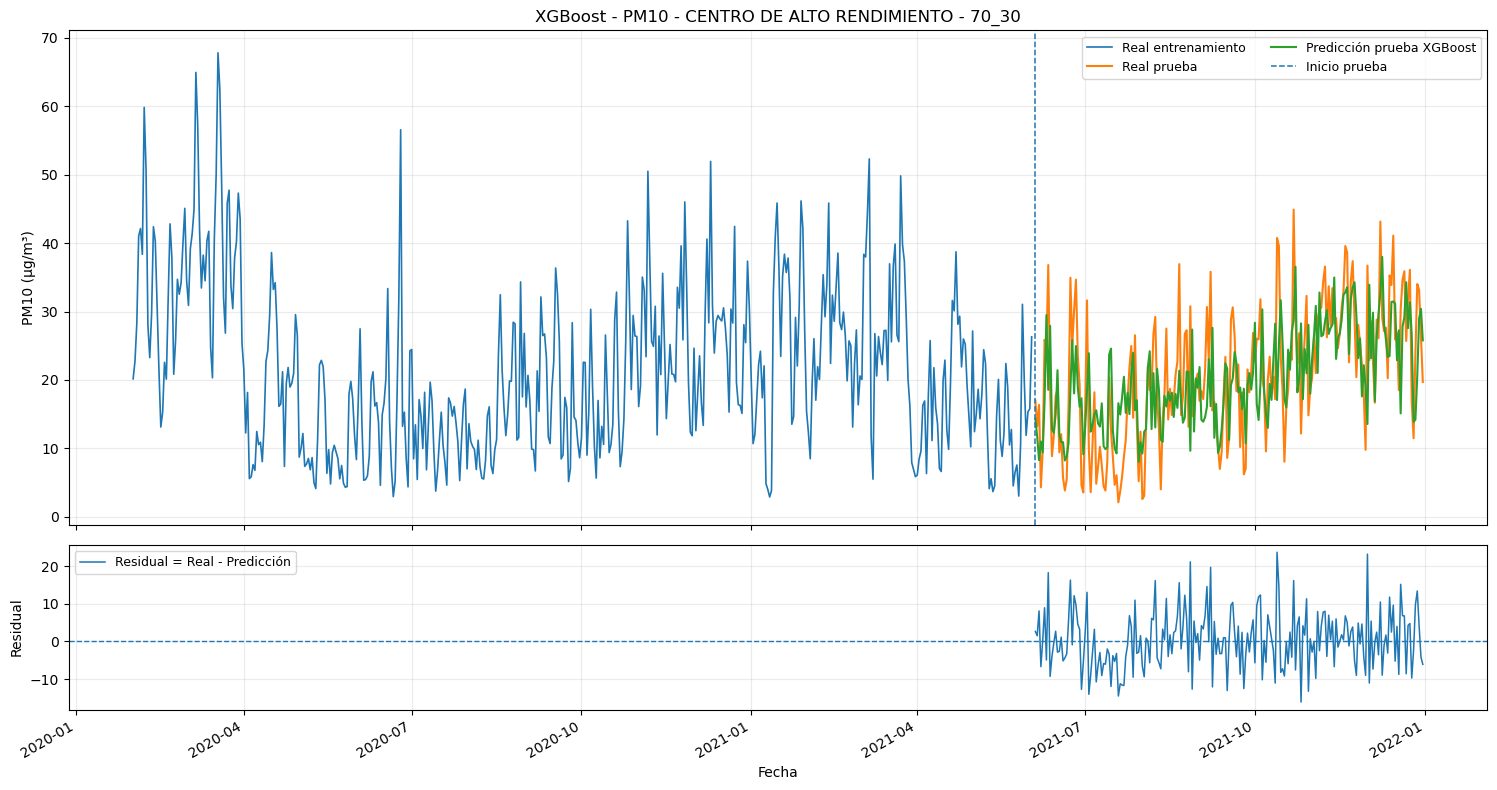

70_30 | H=1 | RMSE=7.7871 | R2=0.3543 | lag=-1 | tiempo=28.07s | RMSE_CV_temporal_purgada


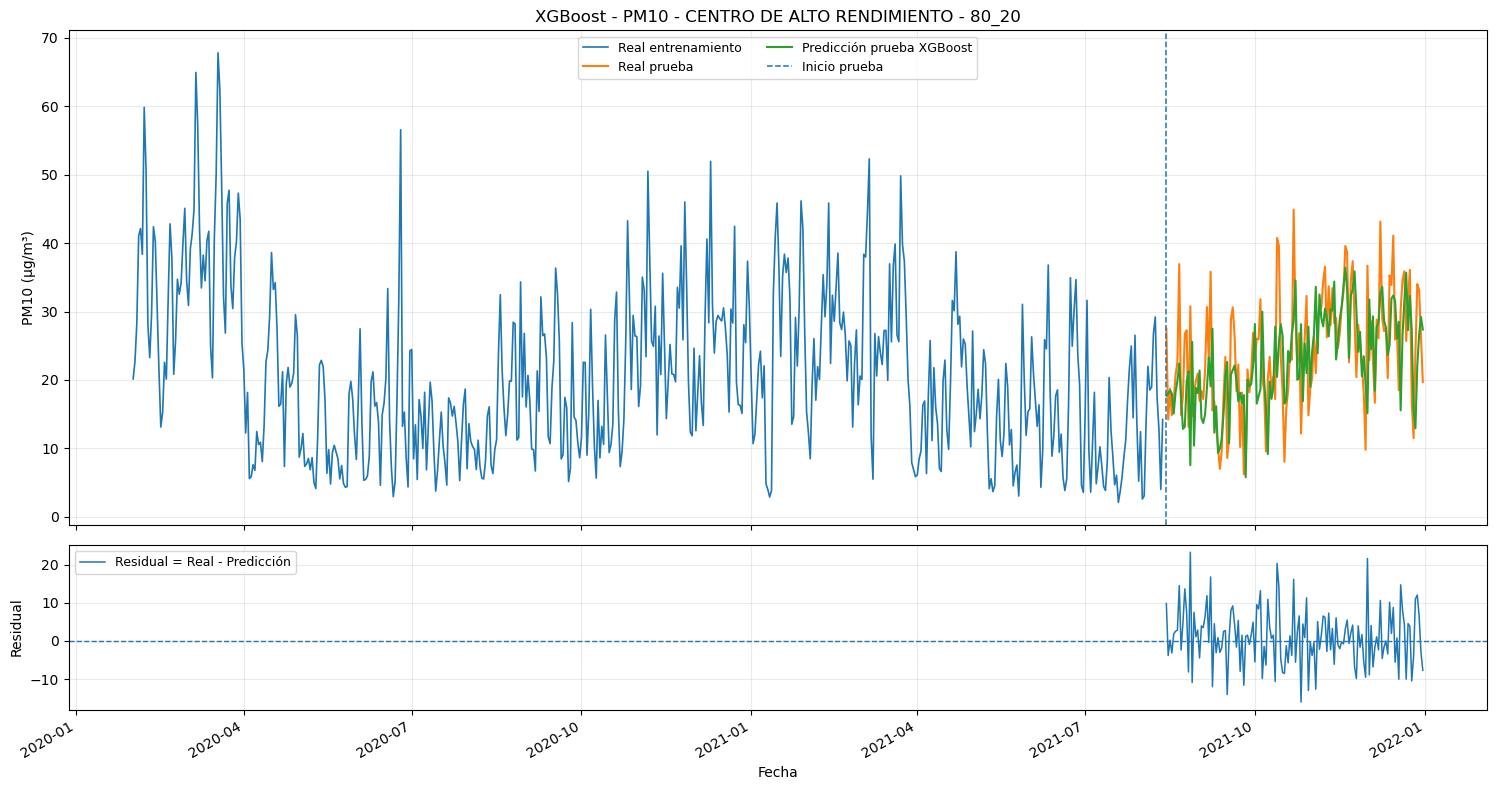

80_20 | H=1 | RMSE=7.5754 | R2=0.1741 | lag=-1 | tiempo=27.48s | RMSE_CV_temporal_purgada


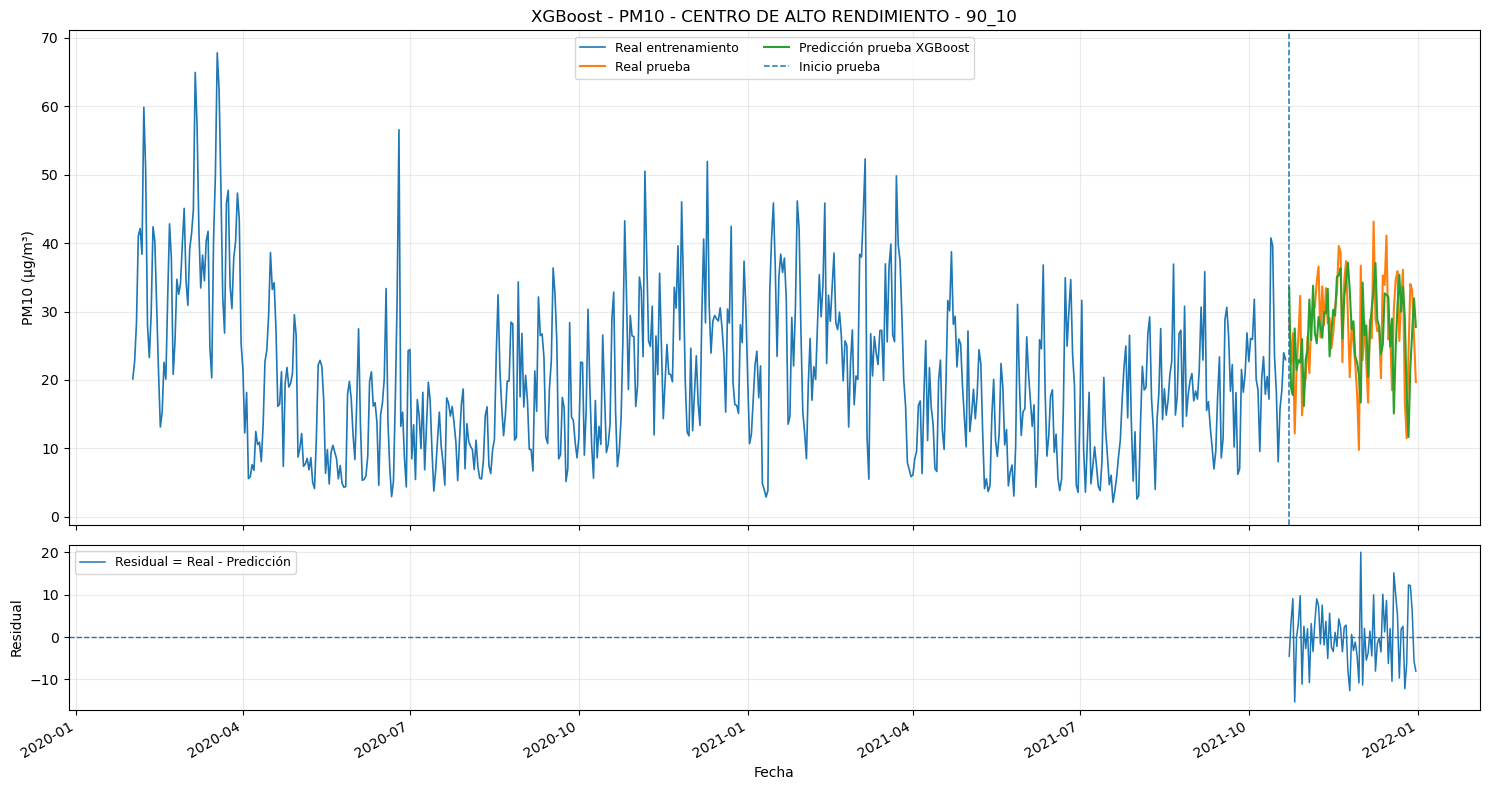

90_10 | H=1 | RMSE=7.2303 | R2=-0.0373 | lag=-1 | tiempo=27.29s | RMSE_CV_temporal_purgada


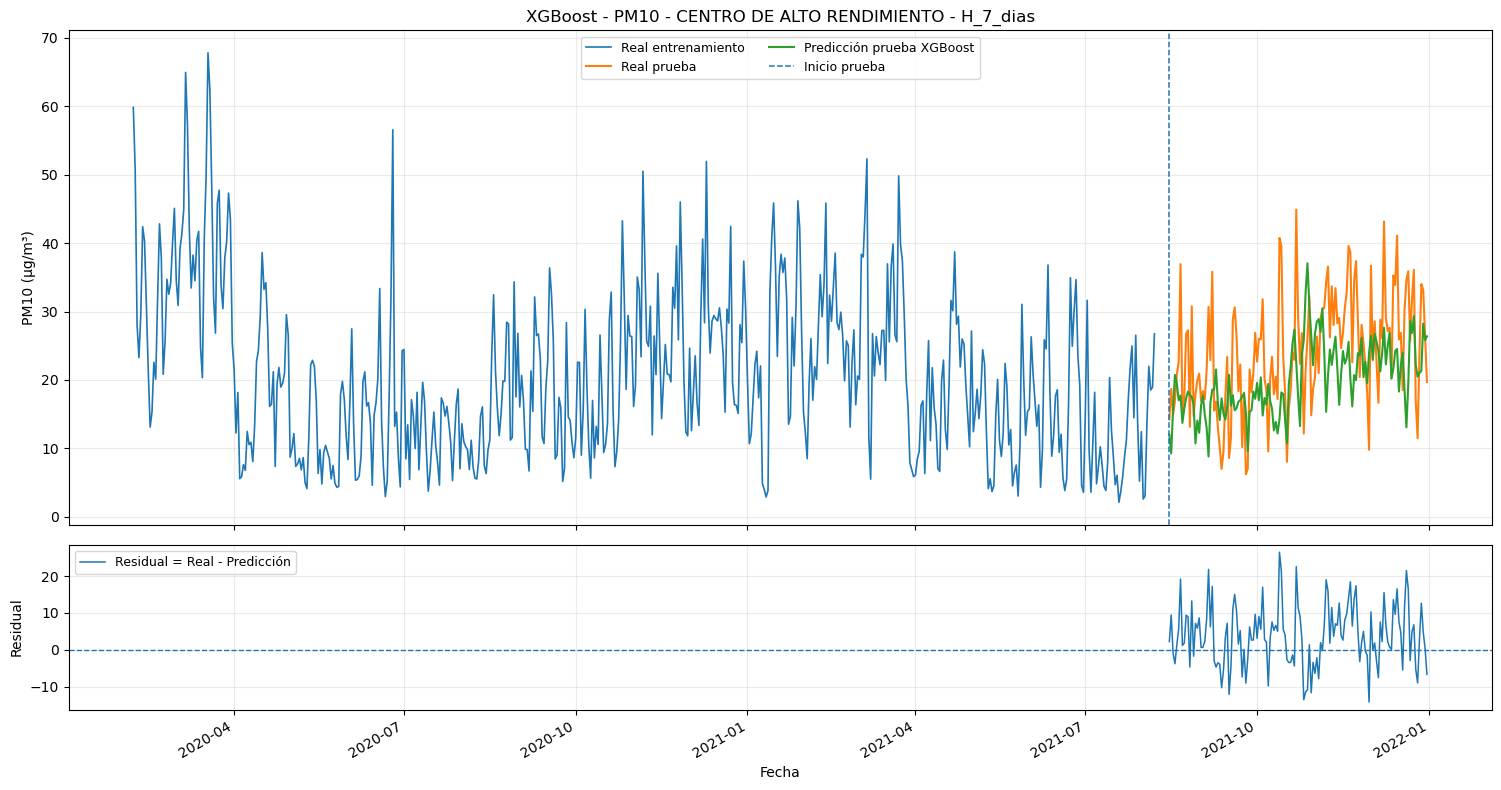

H_7_dias | H=7 | RMSE=9.1316 | R2=-0.1931 | lag=-14 | tiempo=27.12s | RMSE_CV_temporal_purgada


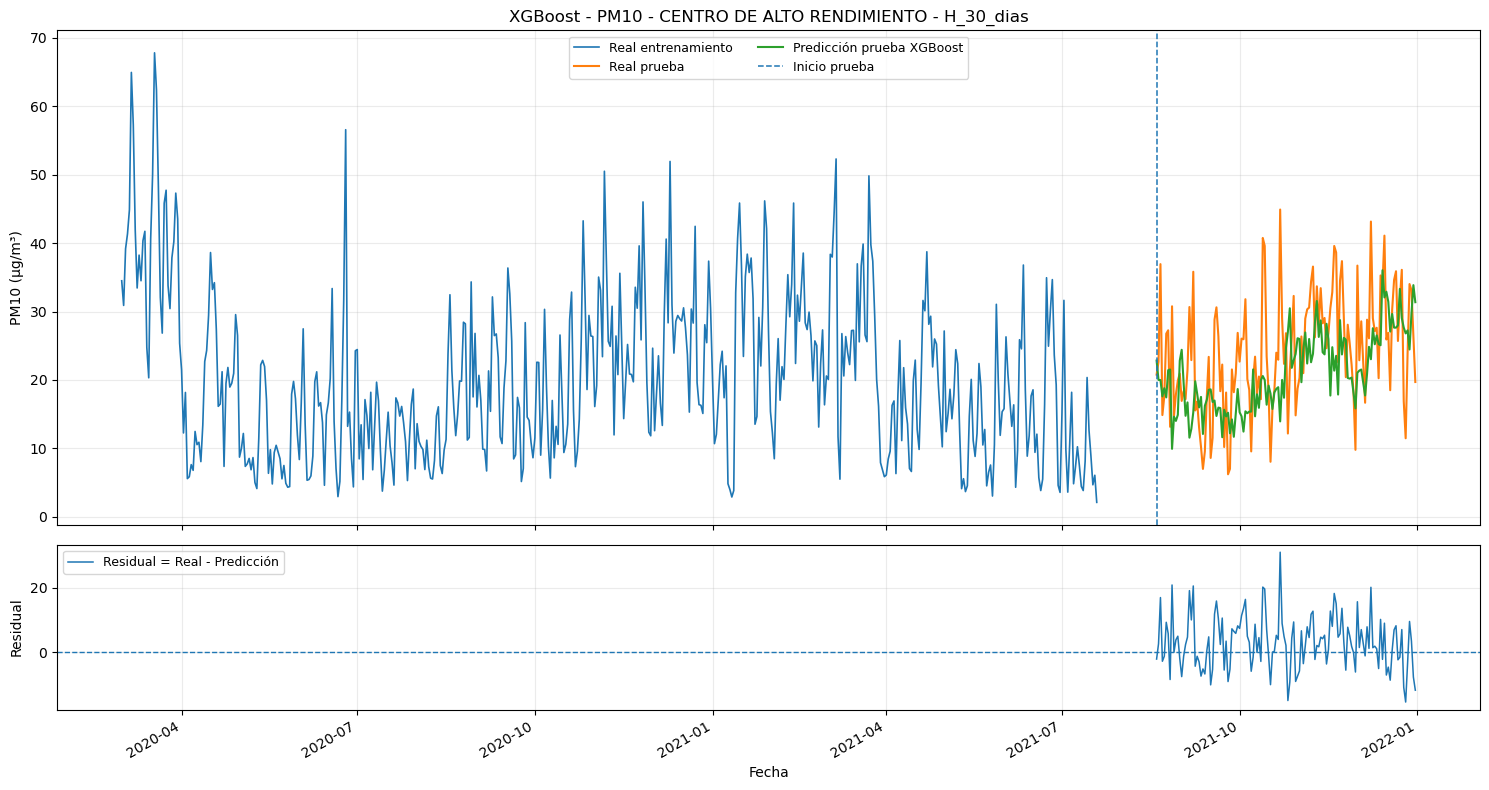

H_30_dias | H=30 | RMSE=8.7643 | R2=-0.0971 | lag=-2 | tiempo=27.73s | RMSE_CV_temporal_purgada


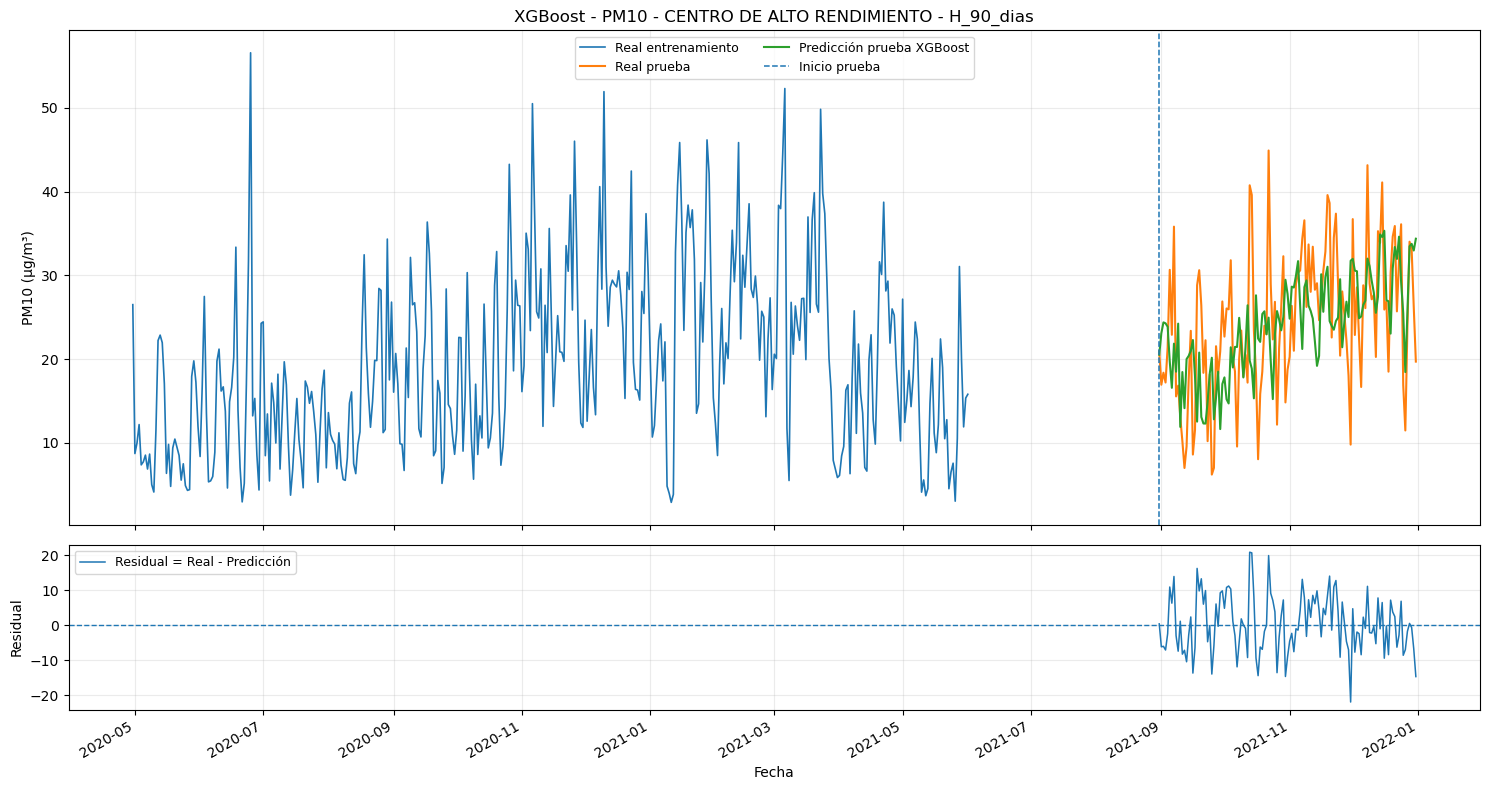

H_90_dias | H=90 | RMSE=8.2171 | R2=0.0573 | lag=-8 | tiempo=24.84s | RMSE_CV_temporal_purgada

XGBoost | Estación=CENTRO DE ALTO RENDIMIENTO | Target=PM25


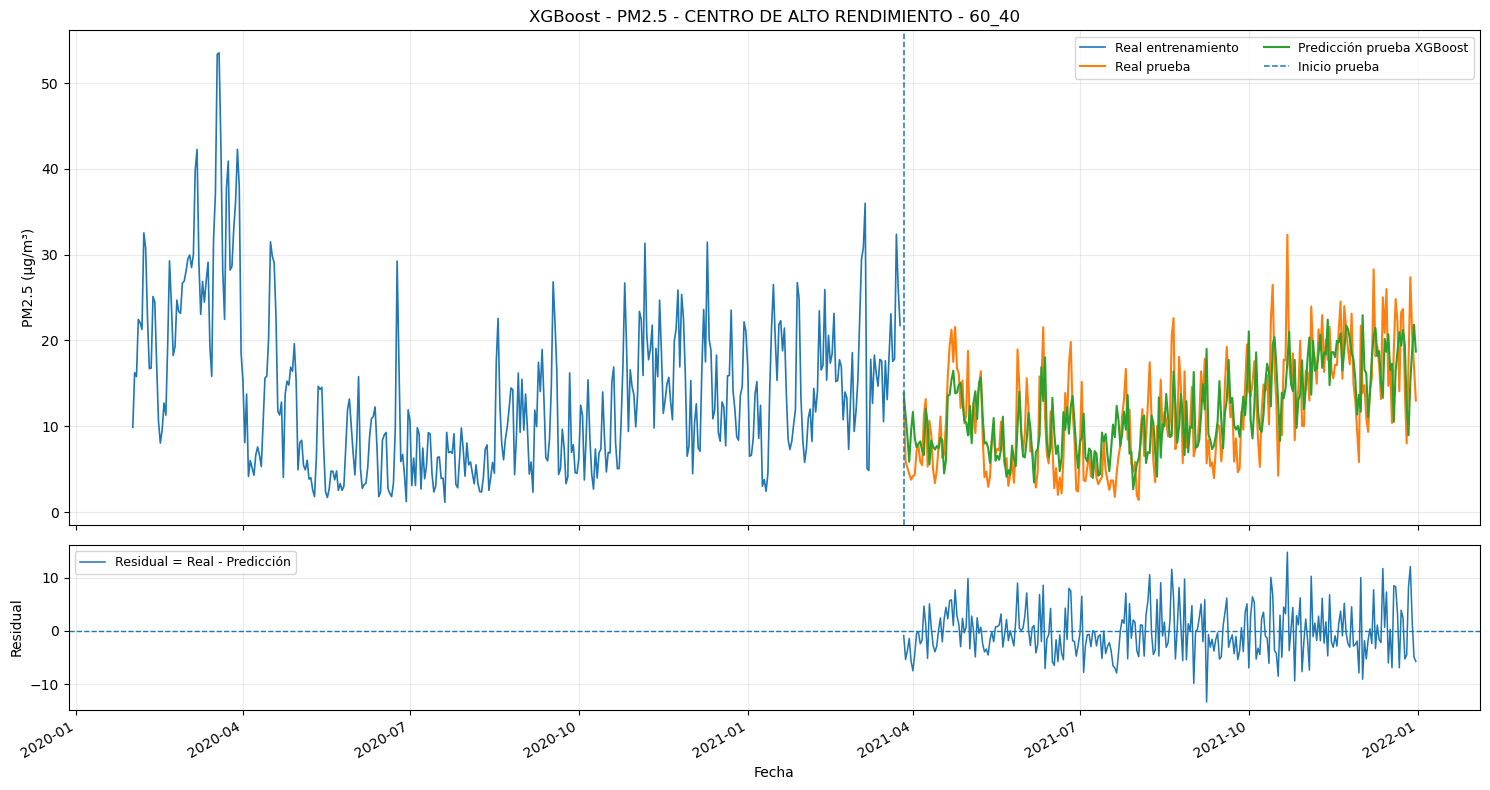

60_40 | H=1 | RMSE=4.6216 | R2=0.4457 | lag=-1 | tiempo=27.24s | RMSE_CV_temporal_purgada


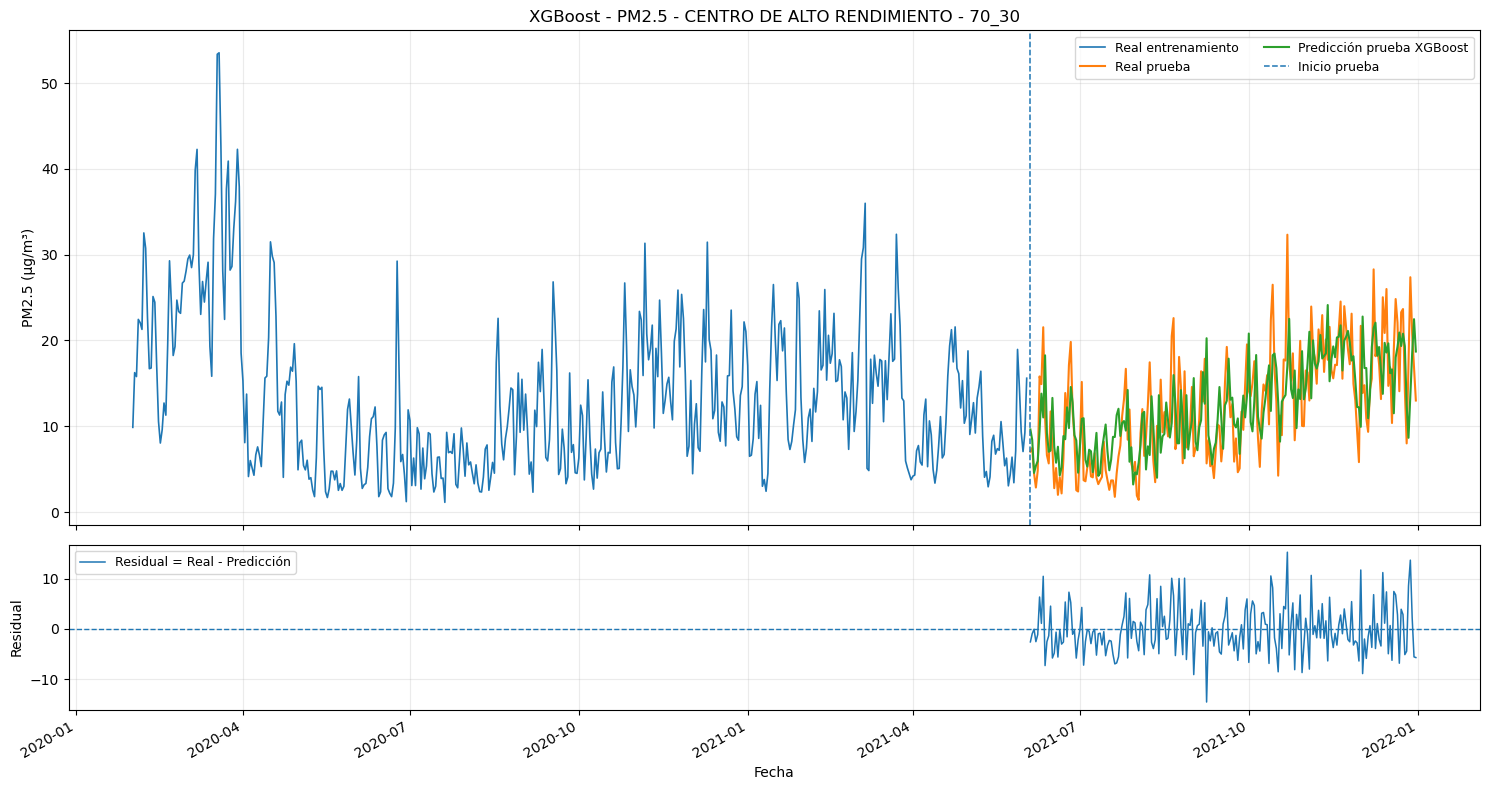

70_30 | H=1 | RMSE=4.9364 | R2=0.4141 | lag=-1 | tiempo=27.97s | RMSE_CV_temporal_purgada


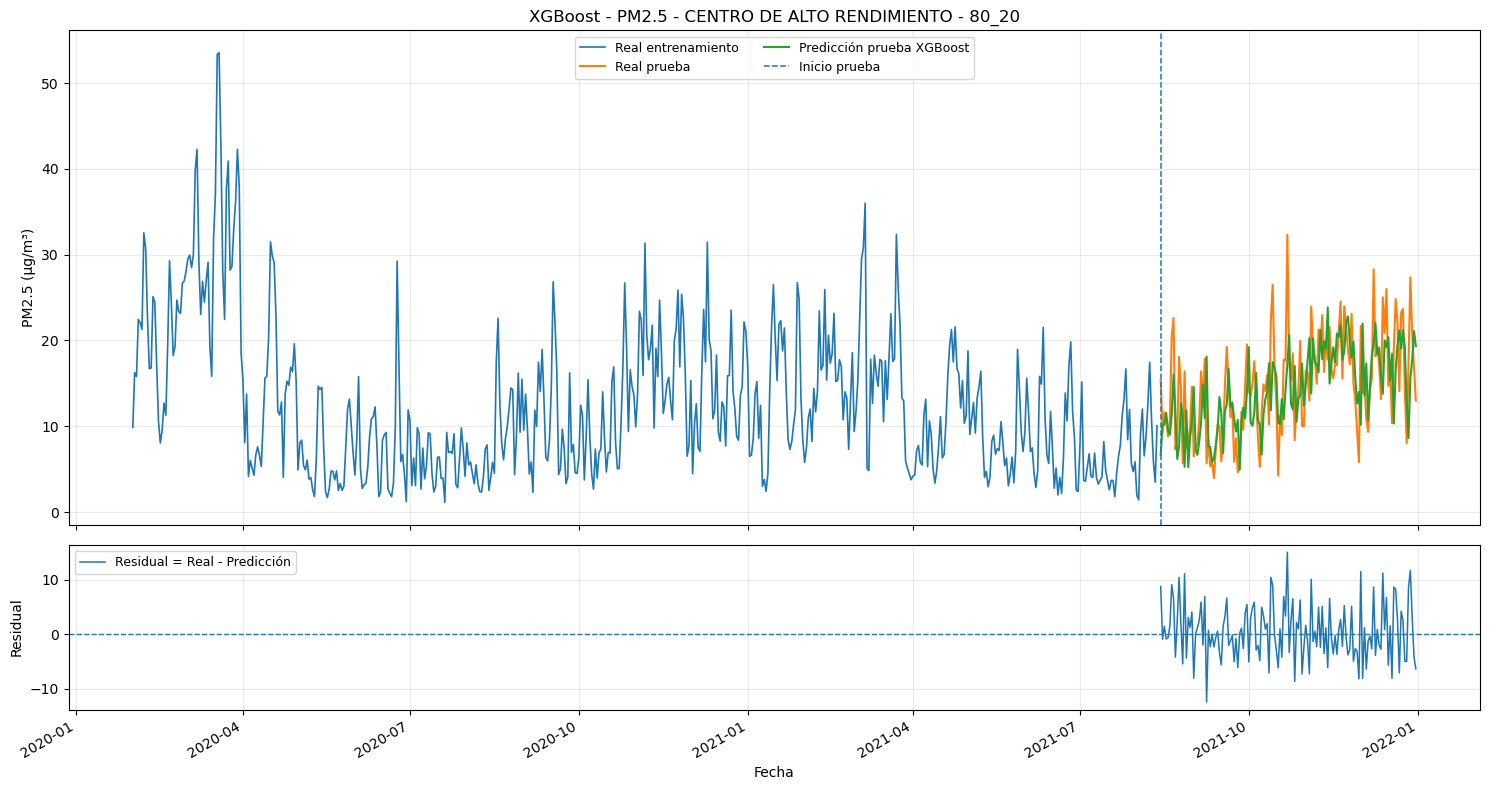

80_20 | H=1 | RMSE=5.2335 | R2=0.1946 | lag=-1 | tiempo=28.52s | RMSE_CV_temporal_purgada


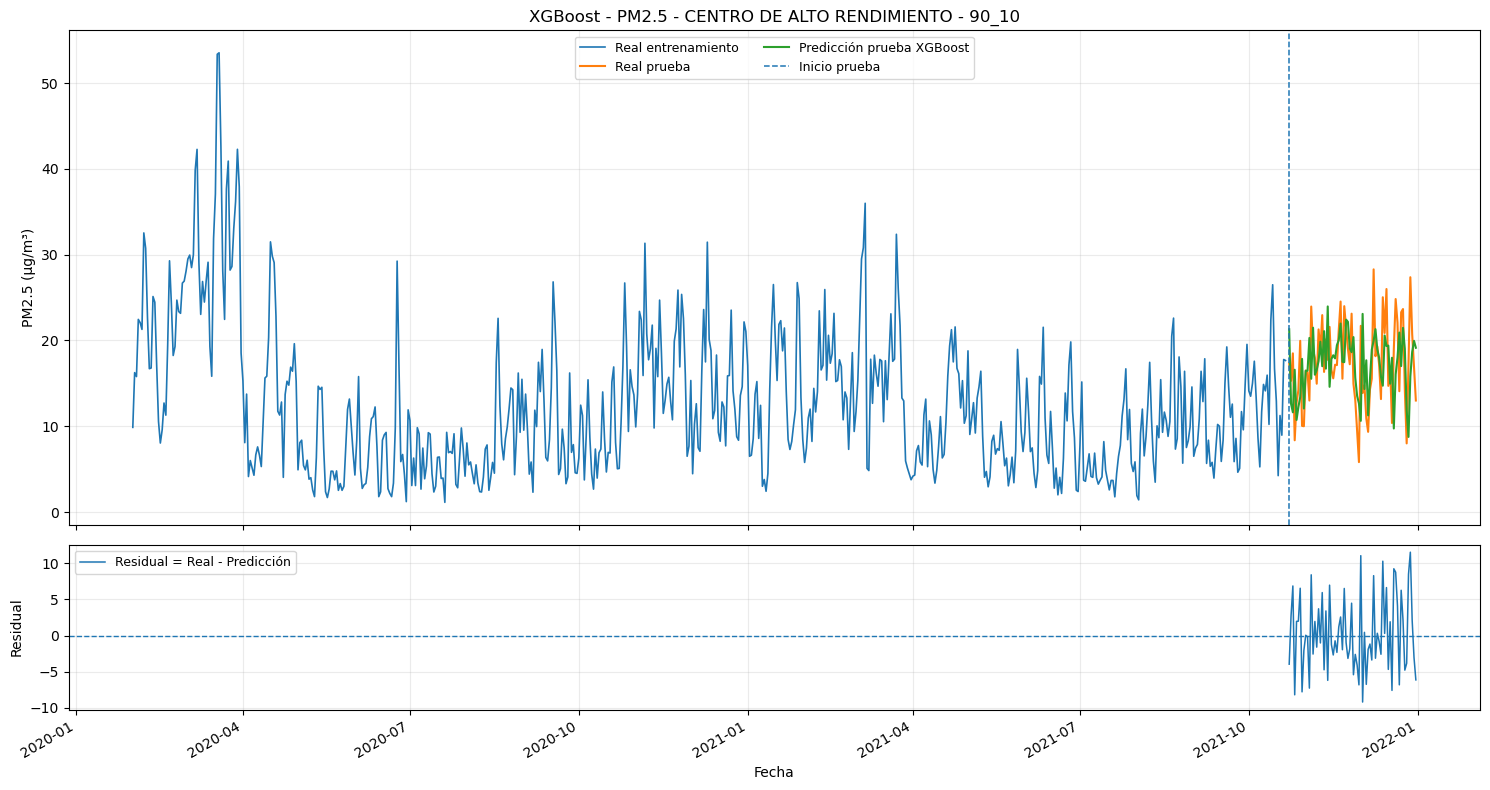

90_10 | H=1 | RMSE=5.2431 | R2=-0.1549 | lag=-1 | tiempo=29.37s | RMSE_CV_temporal_purgada


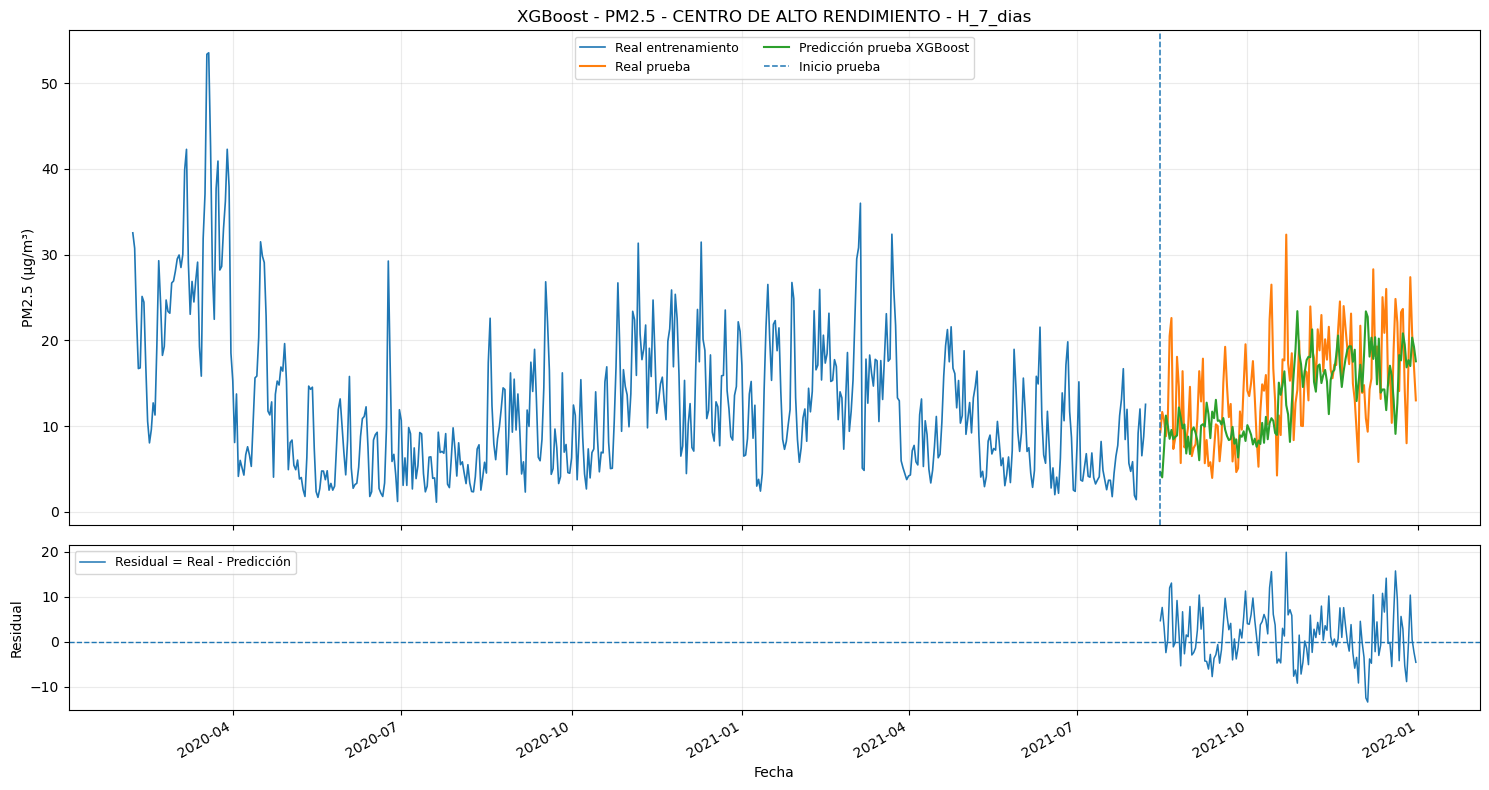

H_7_dias | H=7 | RMSE=6.0909 | R2=-0.0832 | lag=-14 | tiempo=28.25s | RMSE_CV_temporal_purgada


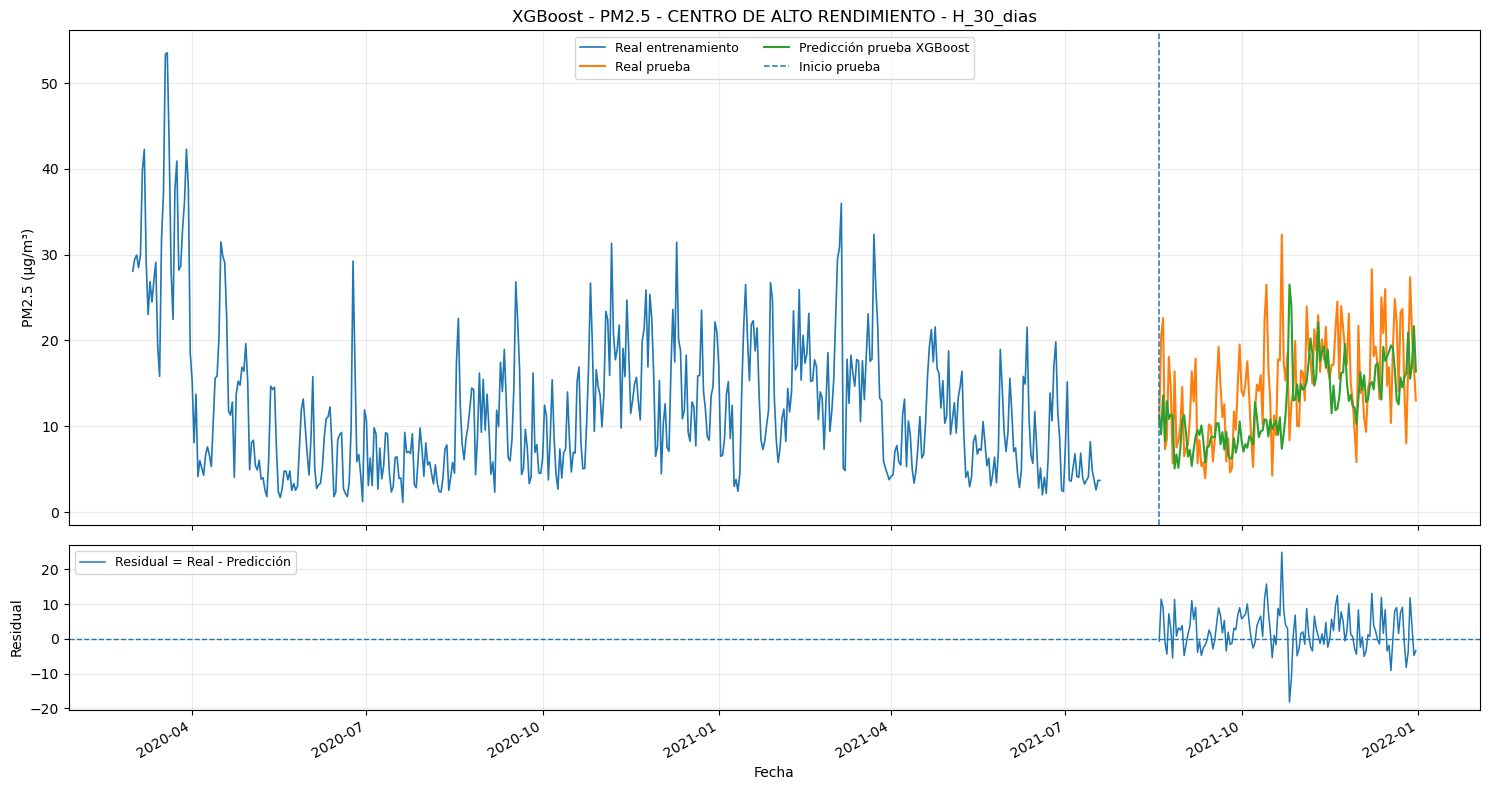

H_30_dias | H=30 | RMSE=6.2412 | R2=-0.1268 | lag=-4 | tiempo=26.42s | RMSE_CV_temporal_purgada


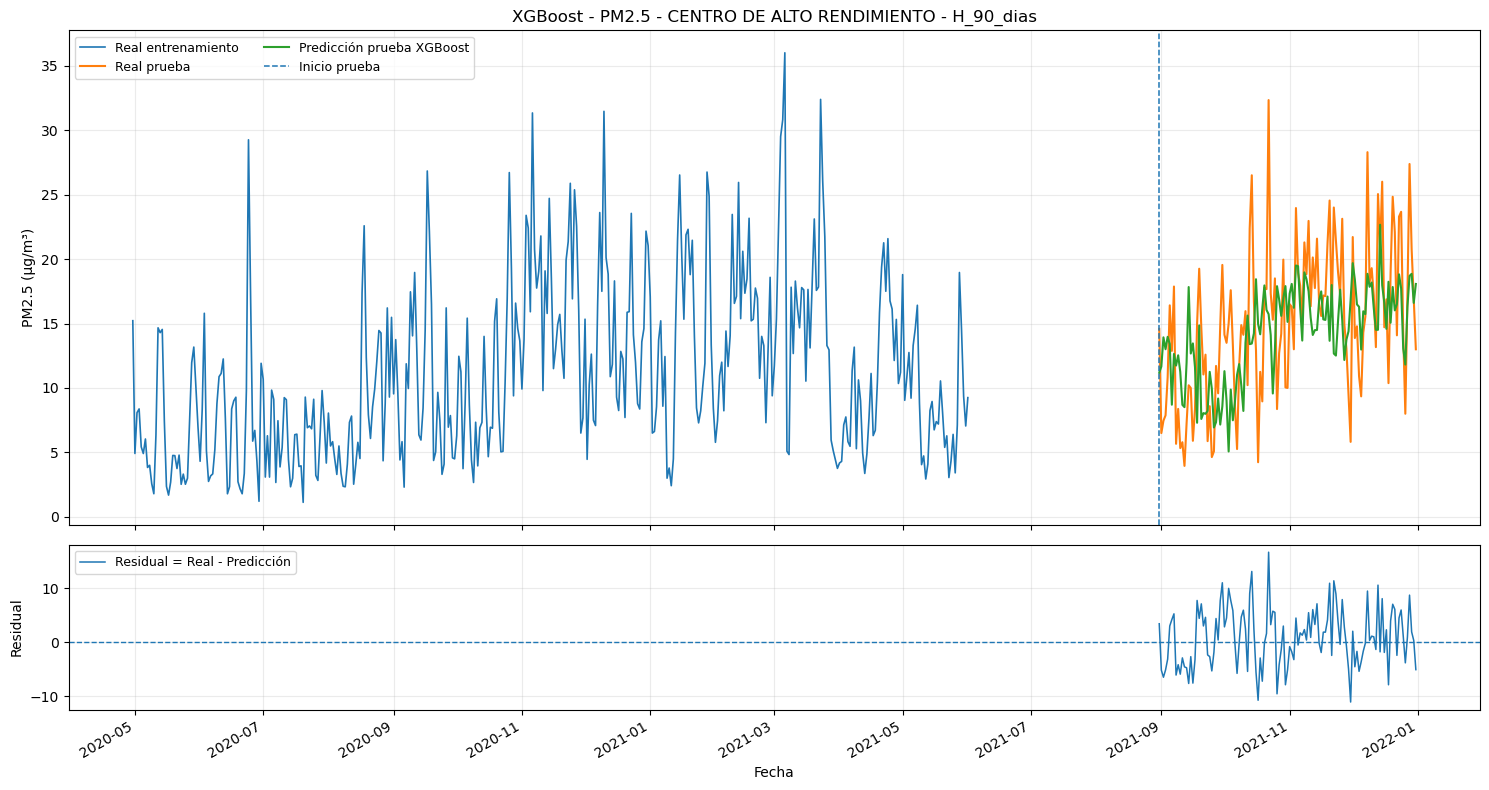

H_90_dias | H=90 | RMSE=5.4652 | R2=0.1322 | lag=-7 | tiempo=21.23s | RMSE_CV_temporal_purgada

XGBoost | Estación=KENNEDY | Target=PM10


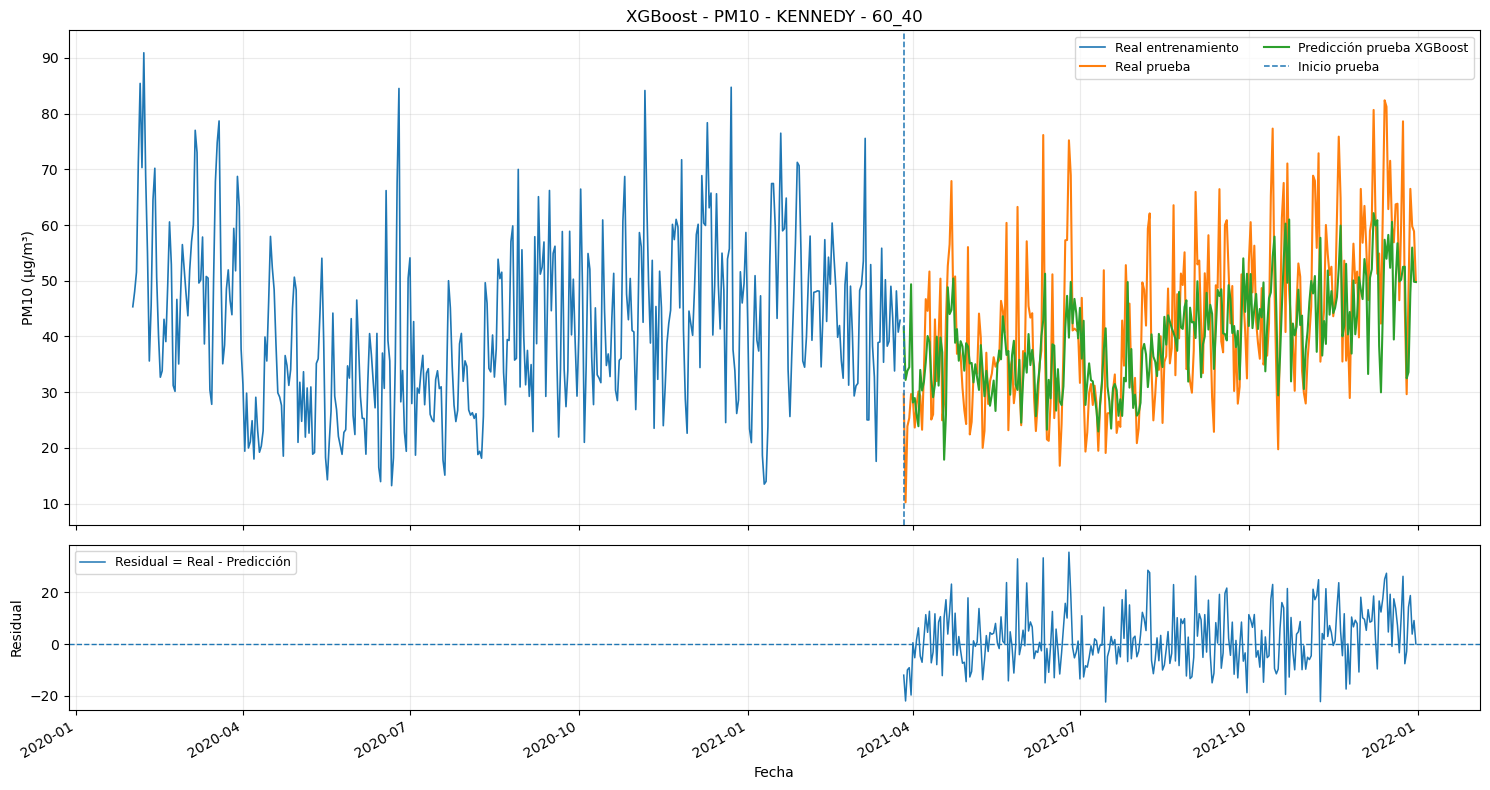

60_40 | H=1 | RMSE=11.4814 | R2=0.3638 | lag=-1 | tiempo=27.21s | RMSE_CV_temporal_purgada


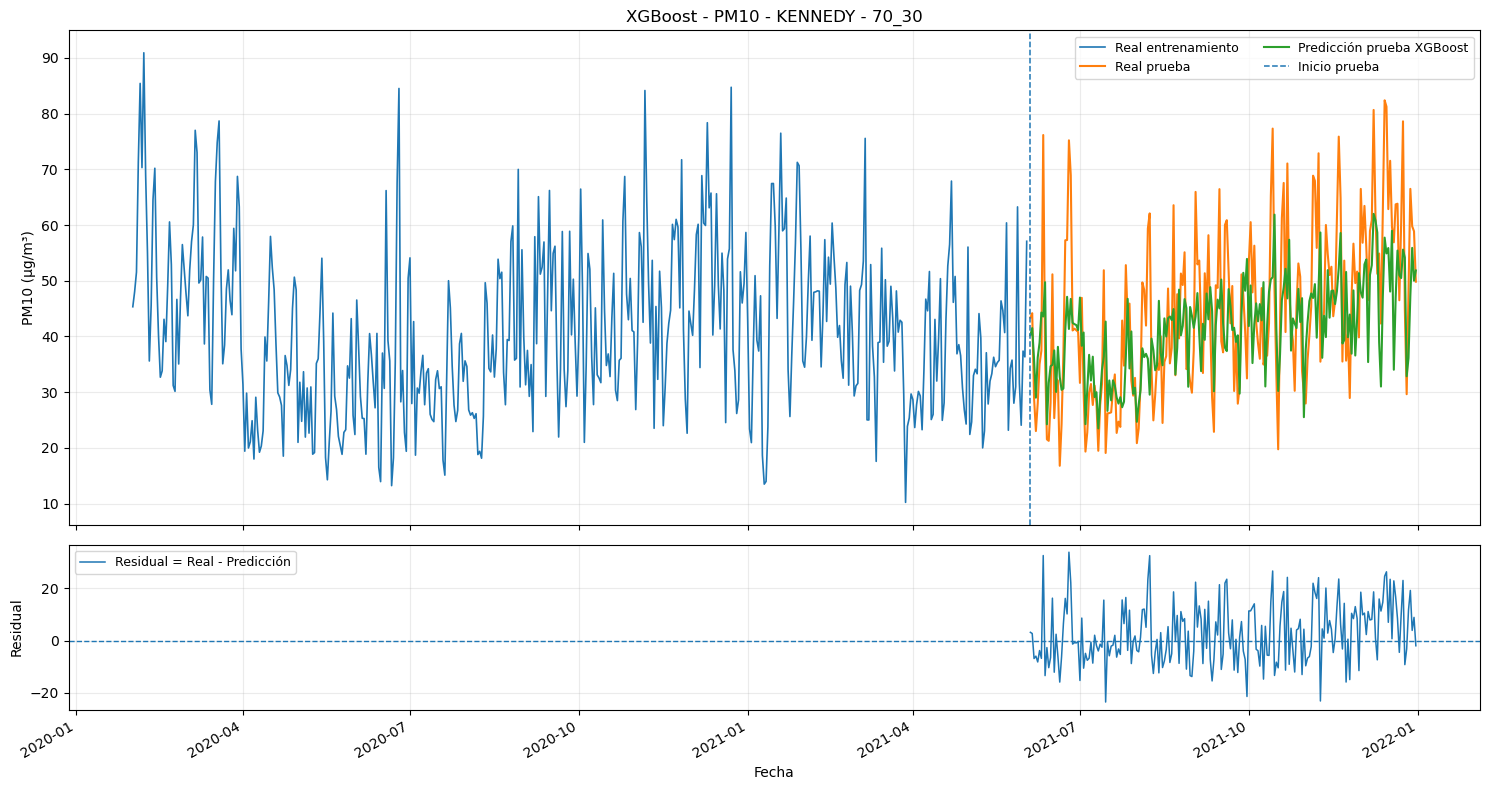

70_30 | H=1 | RMSE=11.9248 | R2=0.3406 | lag=-1 | tiempo=26.68s | RMSE_CV_temporal_purgada


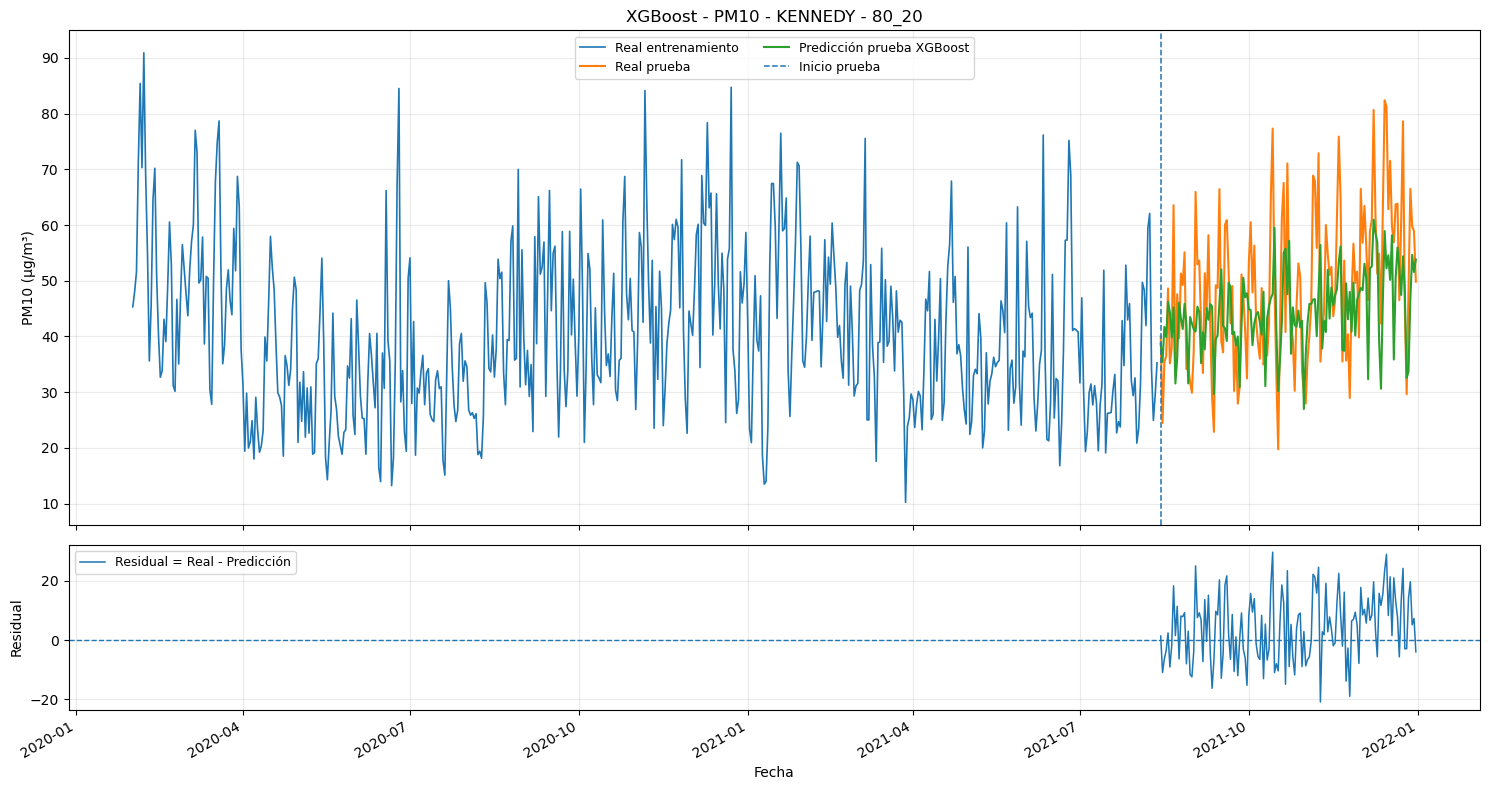

80_20 | H=1 | RMSE=12.0573 | R2=0.1928 | lag=-1 | tiempo=28.41s | RMSE_CV_temporal_purgada


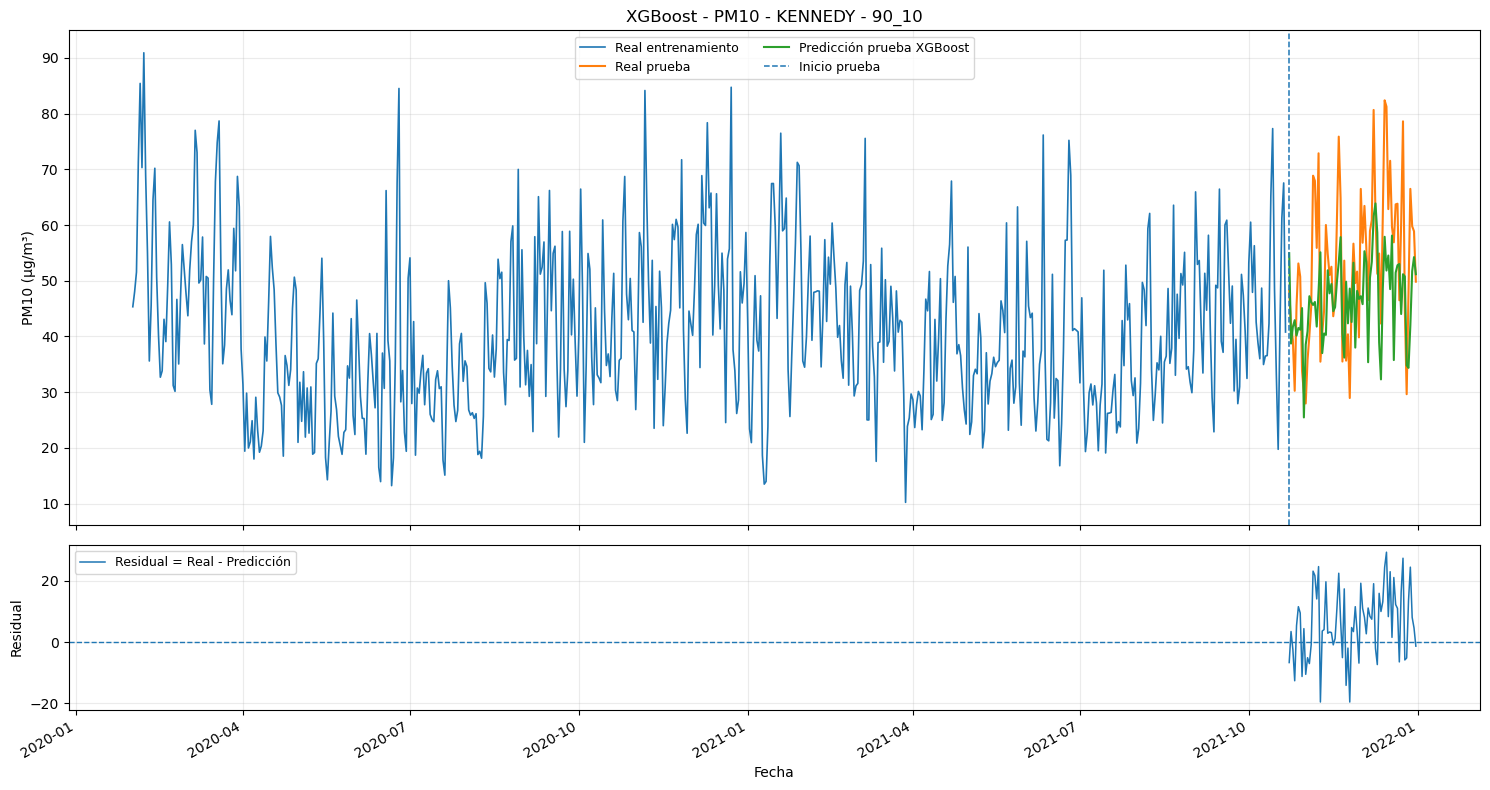

90_10 | H=1 | RMSE=13.0010 | R2=0.0451 | lag=-1 | tiempo=26.56s | RMSE_CV_temporal_purgada


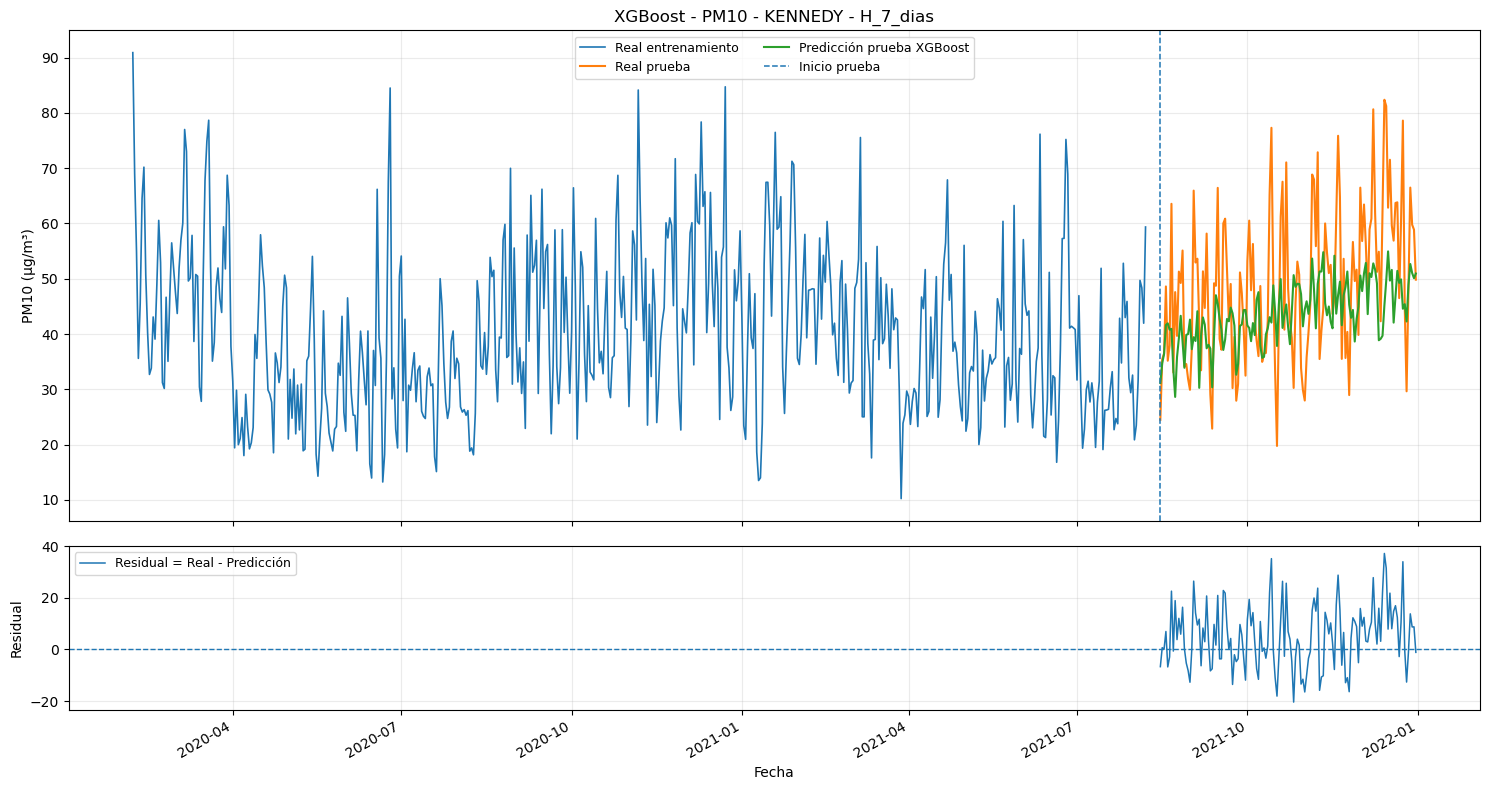

H_7_dias | H=7 | RMSE=13.2296 | R2=0.0322 | lag=0 | tiempo=26.89s | RMSE_CV_temporal_purgada


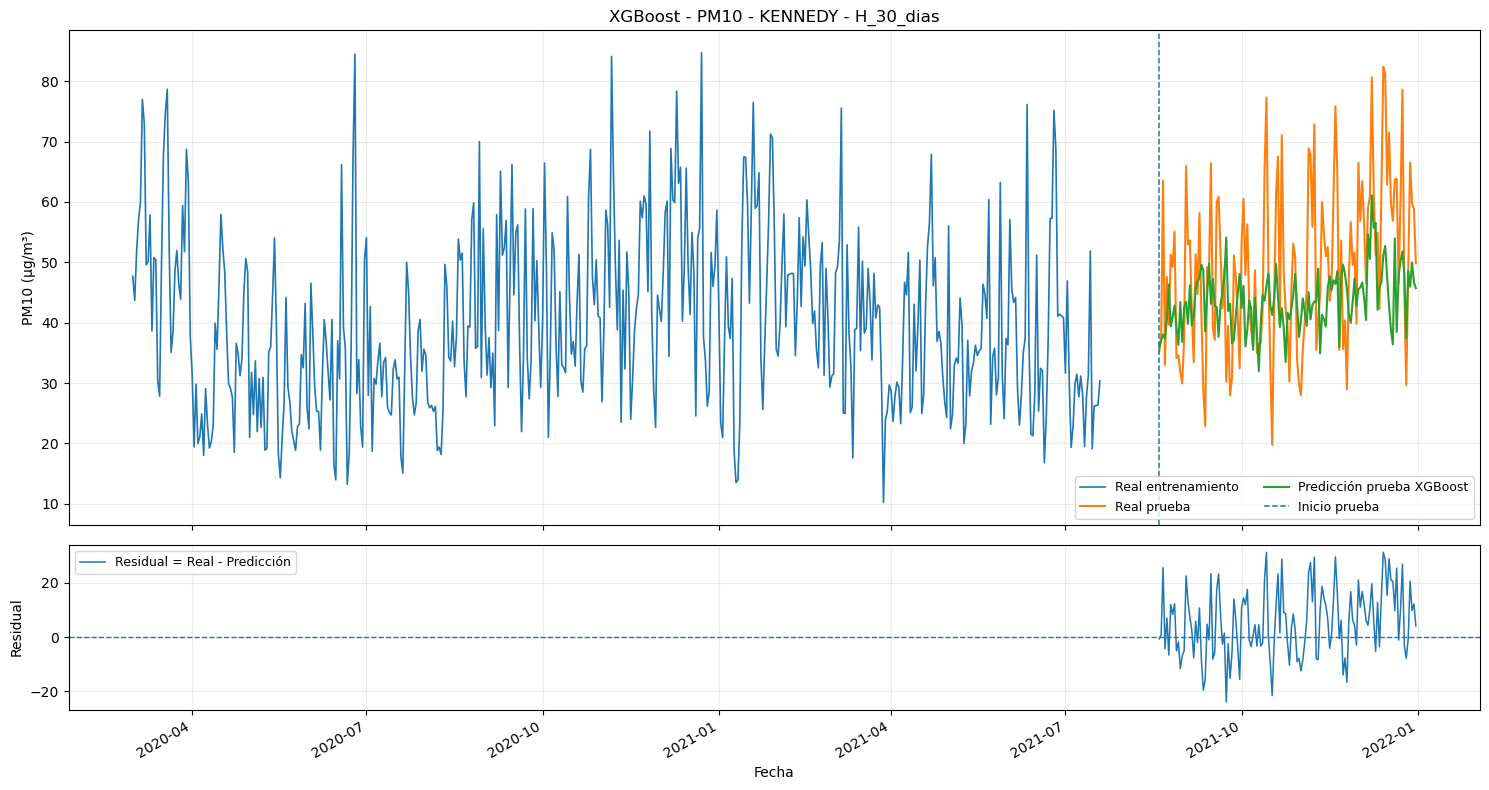

H_30_dias | H=30 | RMSE=13.5048 | R2=-0.0178 | lag=0 | tiempo=28.32s | RMSE_CV_temporal_purgada


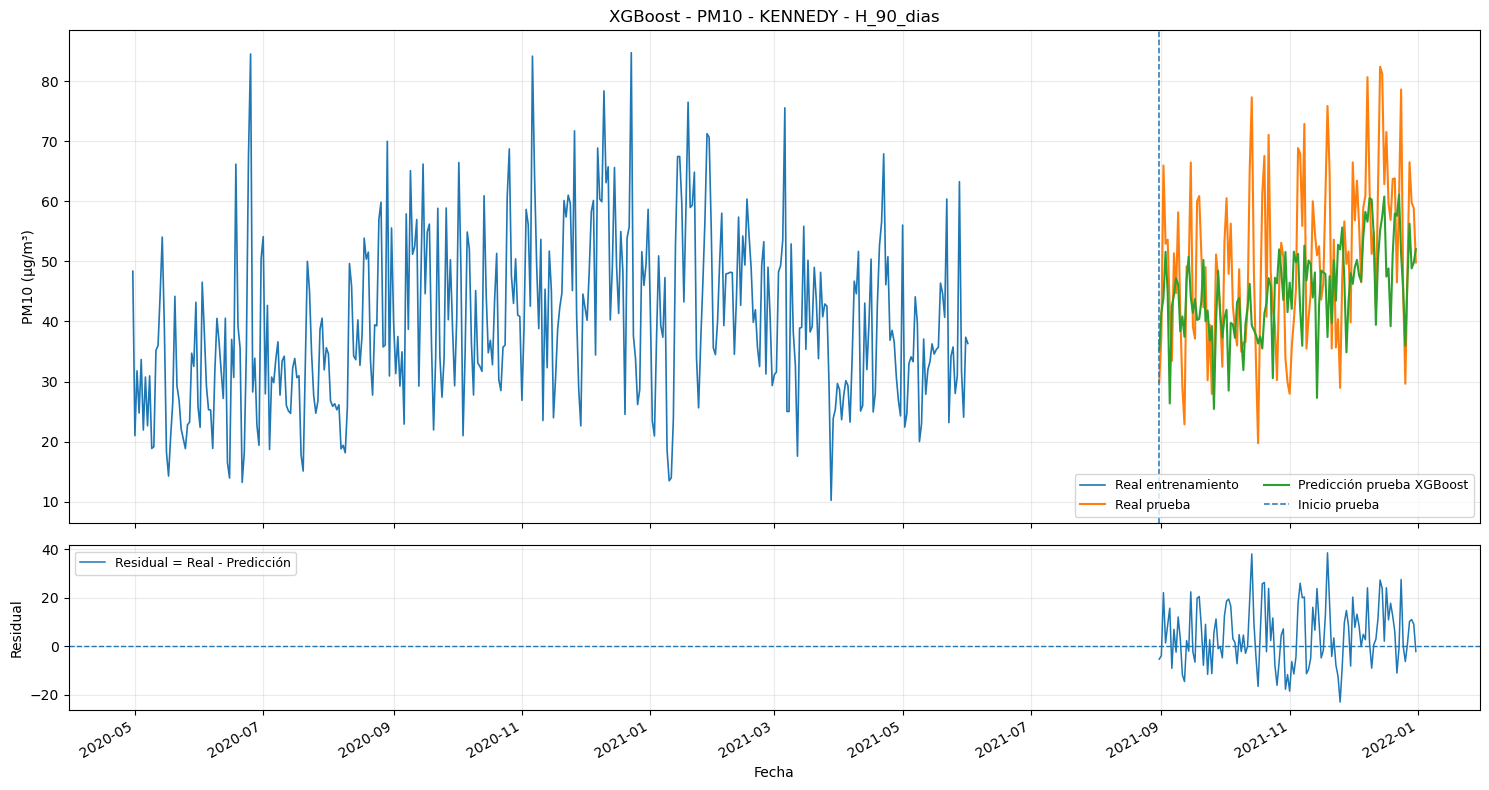

H_90_dias | H=90 | RMSE=13.3811 | R2=0.0198 | lag=7 | tiempo=25.67s | RMSE_CV_temporal_purgada

XGBoost | Estación=KENNEDY | Target=PM25


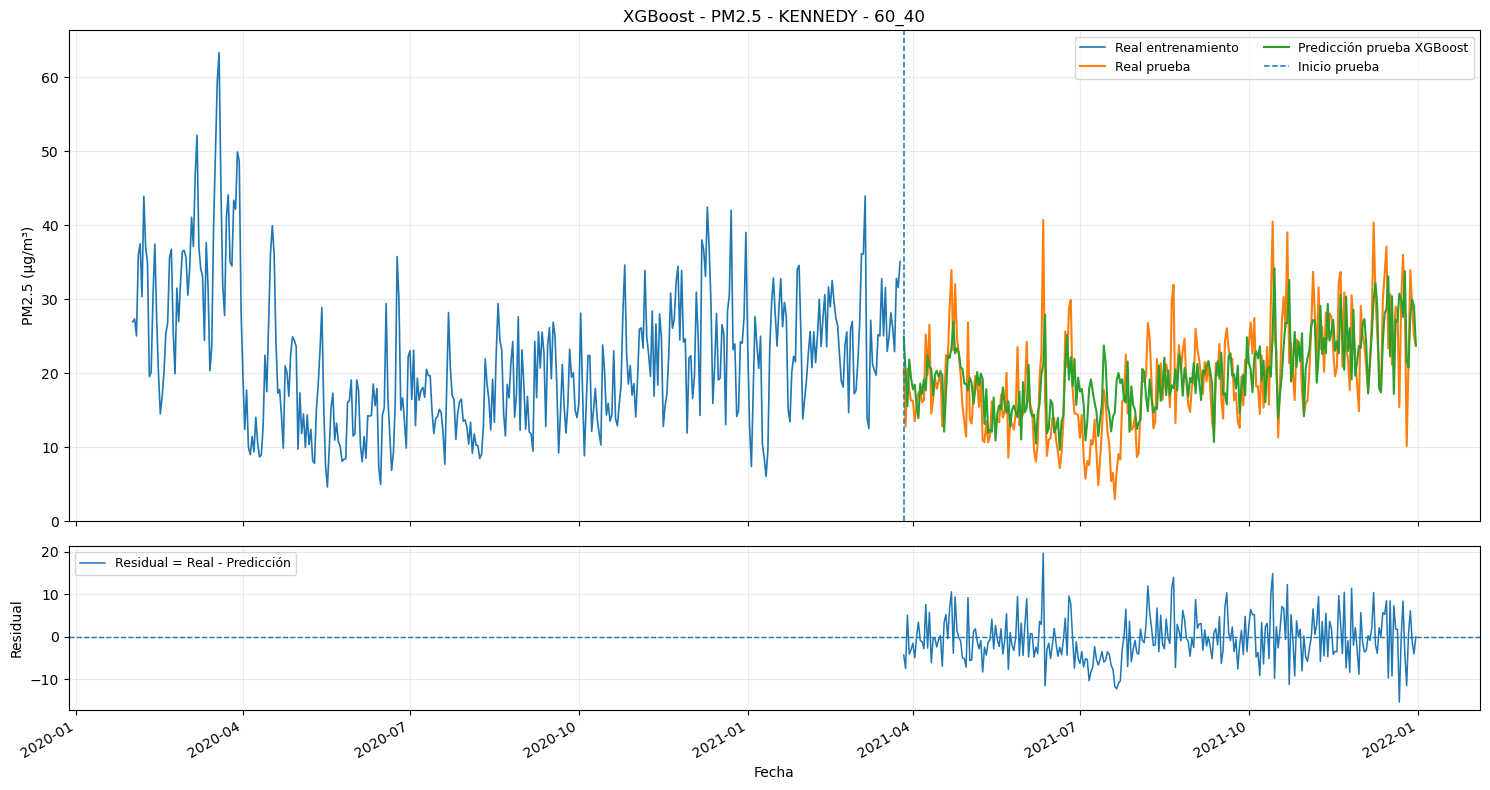

60_40 | H=1 | RMSE=5.5130 | R2=0.3836 | lag=-1 | tiempo=25.62s | RMSE_CV_temporal_purgada


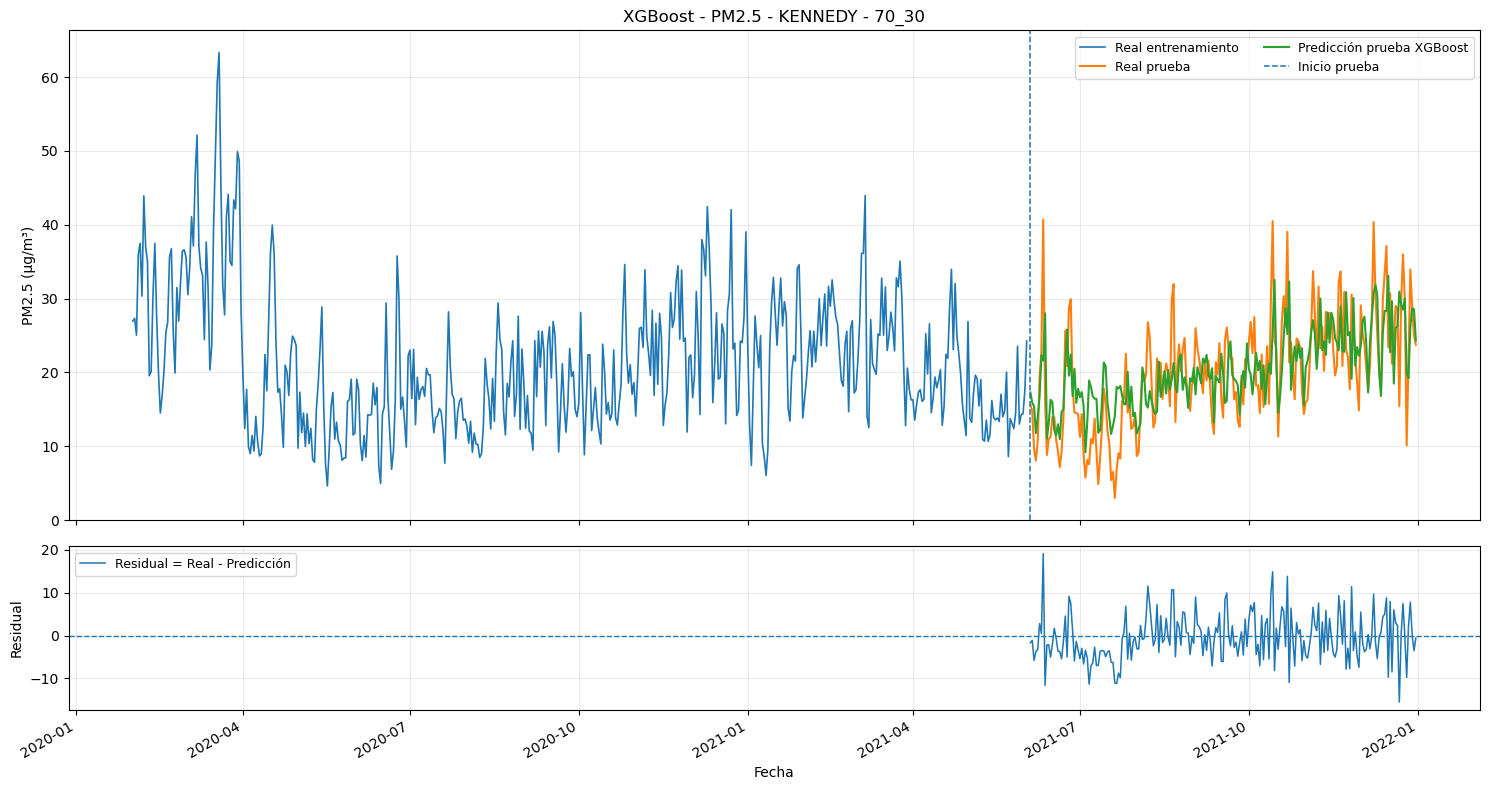

70_30 | H=1 | RMSE=5.5653 | R2=0.4421 | lag=-1 | tiempo=23.68s | RMSE_CV_temporal_purgada


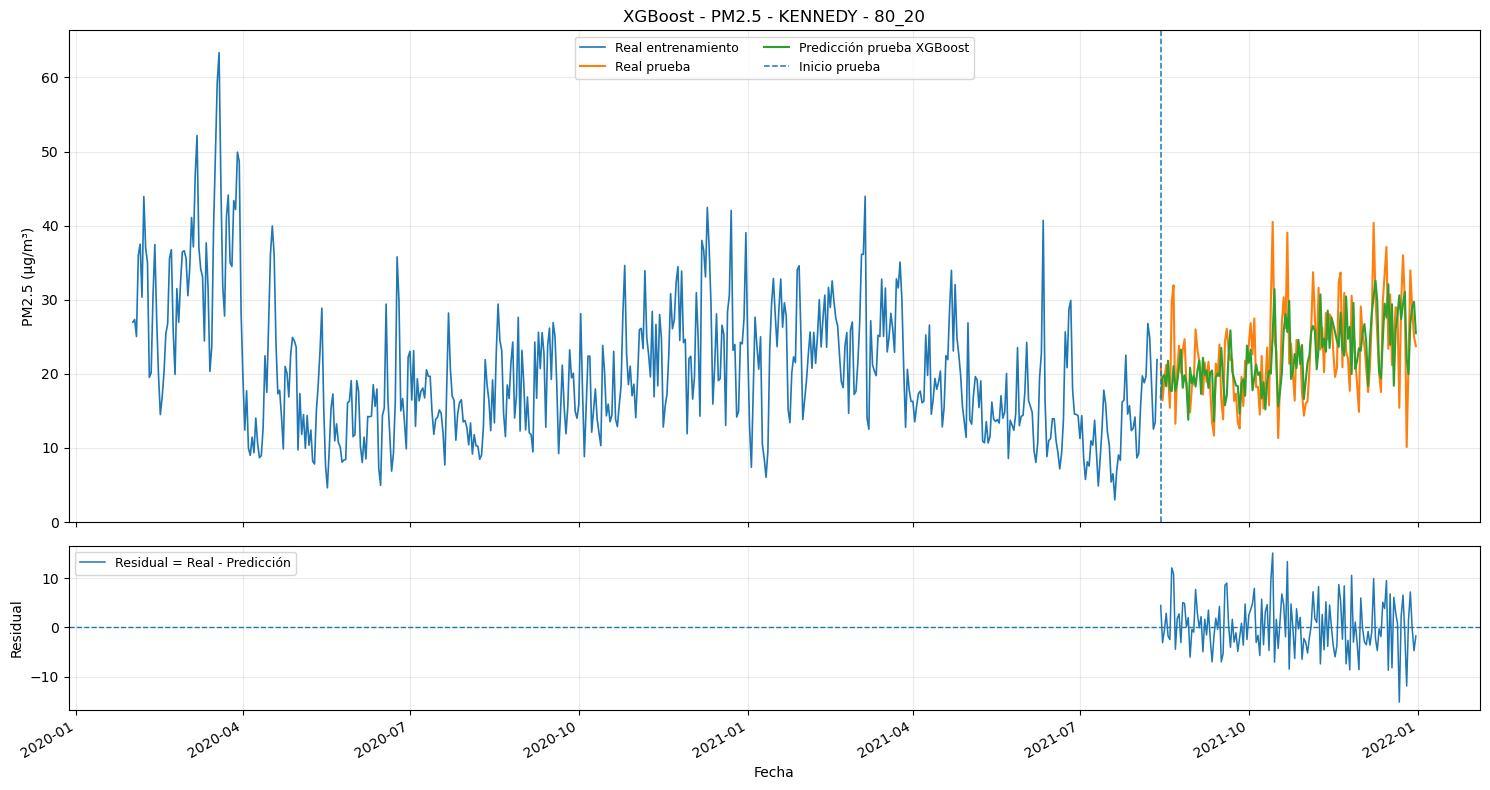

80_20 | H=1 | RMSE=5.3648 | R2=0.2207 | lag=-1 | tiempo=29.12s | RMSE_CV_temporal_purgada


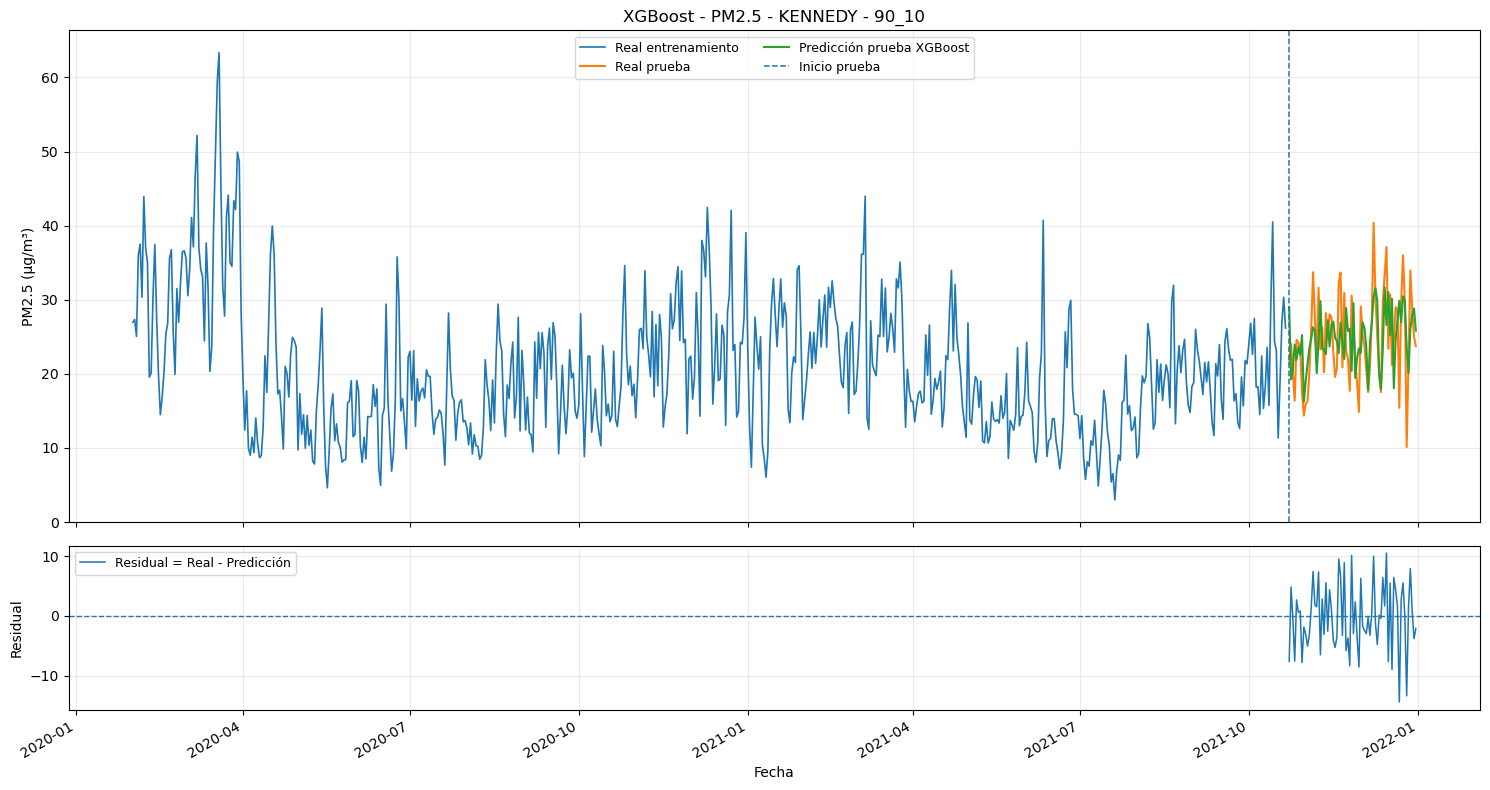

90_10 | H=1 | RMSE=5.5880 | R2=0.1253 | lag=-1 | tiempo=29.19s | RMSE_CV_temporal_purgada


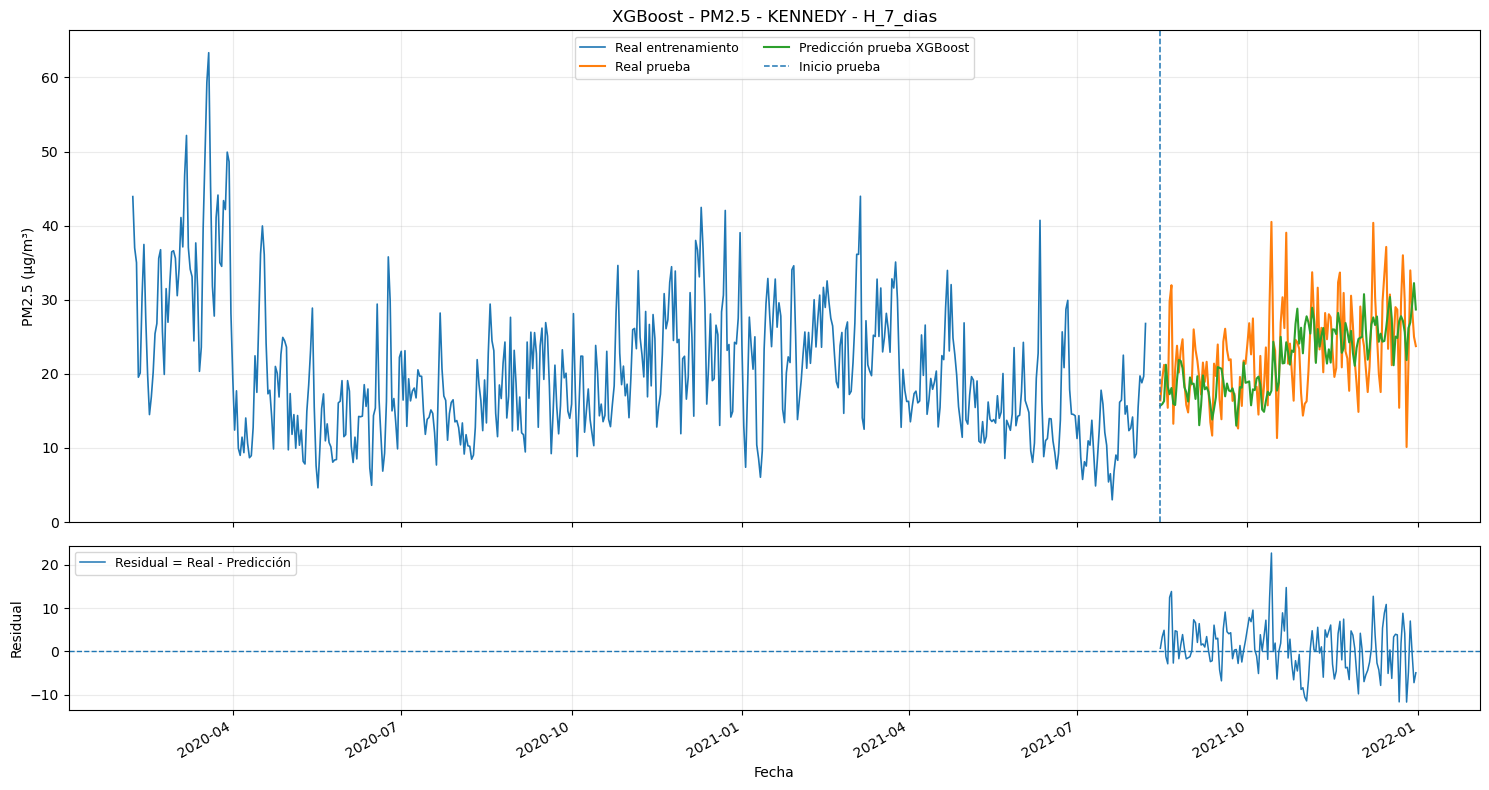

H_7_dias | H=7 | RMSE=5.8205 | R2=0.0888 | lag=-14 | tiempo=24.33s | RMSE_CV_temporal_purgada


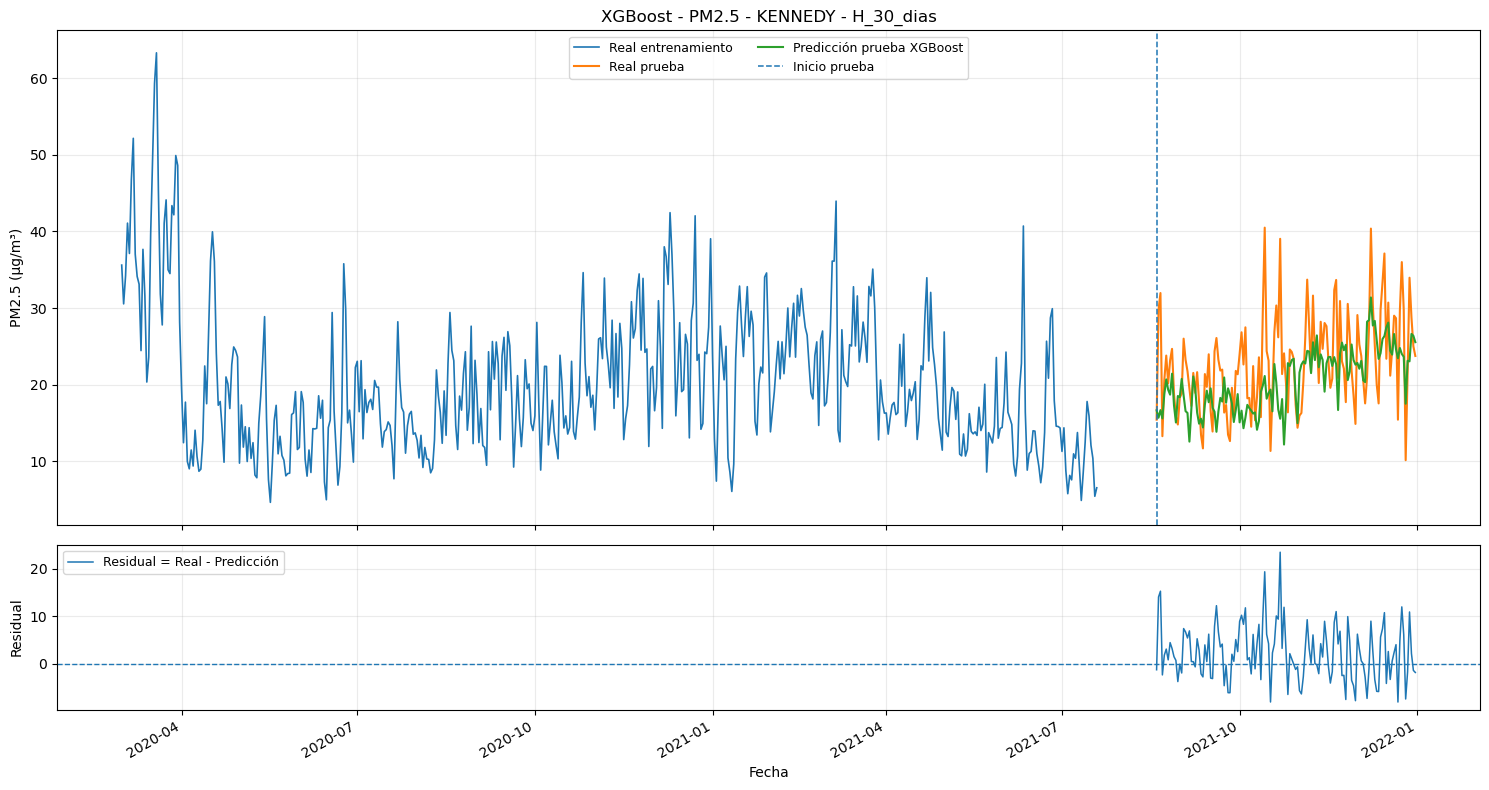

H_30_dias | H=30 | RMSE=6.2298 | R2=-0.0268 | lag=7 | tiempo=27.01s | RMSE_CV_temporal_purgada


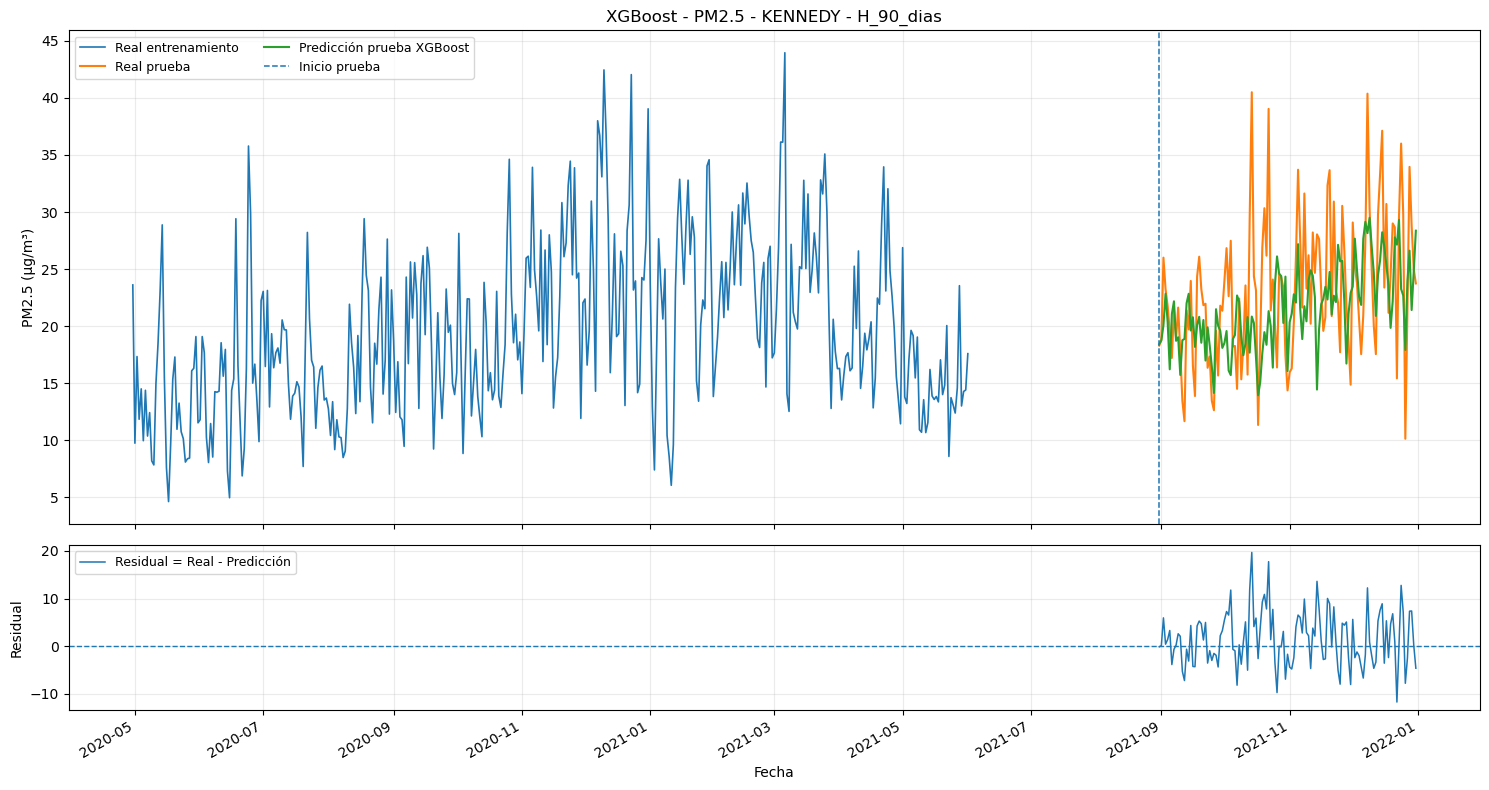

H_90_dias | H=90 | RMSE=5.9469 | R2=0.0685 | lag=-14 | tiempo=25.91s | RMSE_CV_temporal_purgada

Modelado finalizado.


In [7]:

# ============================================================
# 8. EJECUCIÓN DEL PROTOCOLO
# ============================================================
metricas_rows = []
predicciones_rows = []
config_rows = []
tiempos_rows = []
cv_resumen_rows = []
cv_detalle_rows = []
importancias_rows = []

for estacion in ESTACIONES:
    for target in TARGETS:
        print("\n" + "="*100)
        print(f"{MODELO_NOMBRE} | Estación={estacion} | Target={target}")
        print("="*100)

        for esc in ESCENARIOS:
            escenario = esc["Escenario"]
            h = int(esc["Horizonte_dias"])
            train_frac = float(esc["train_frac"])
            inicio_total = time.perf_counter()

            # ---------- Preparación ----------
            inicio_prep = time.perf_counter()
            data, features = preparar_features_estacion(df_master, estacion, target, h)
            tiempo_prep = time.perf_counter() - inicio_prep

            n = len(data)
            idx_split = int(n * train_frac)

            # Purga externa: evita usar etiquetas de entrenamiento que, al ser y(t+h),
            # pertenezcan al periodo desde el que comienzan las predicciones.
            train_end = idx_split - h
            if train_end < MIN_TRAIN_FINAL or idx_split >= n - 3:
                print(f"OMITIDO {escenario}: datos insuficientes después de purga h={h}. N={n}, train_end={train_end}")
                tiempos_rows.append({
                    "Modelo": MODELO_NOMBRE, "Estacion": estacion, "Variable": target.replace("PM25","PM2.5"),
                    "Tipo_evaluacion": esc["Tipo_evaluacion"], "Escenario": escenario, "Horizonte_dias": h,
                    "Estado": "Omitido_datos_insuficientes", "Tiempo_total_escenario_segundos": time.perf_counter()-inicio_total
                })
                continue

            train = data.iloc[:train_end].copy()
            test = data.iloc[idx_split:].copy()

            X_train, y_train = train[features], train["y"]
            X_test, y_test = test[features], test["y"]
            p_train, p_test = train["Persistencia"], test["Persistencia"]
            fechas_train = pd.to_datetime(train["Fecha_objetivo"])
            fechas_test = pd.to_datetime(test["Fecha_objetivo"])

            # ---------- CV / hiperparámetros ----------
            inicio_cv = time.perf_counter()
            mejores_params, cv_resumen, cv_detalle, metodo_seleccion = seleccionar_hiperparametros(
                X_train, y_train, horizonte=h
            )
            tiempo_cv = time.perf_counter() - inicio_cv

            if not cv_resumen.empty:
                tmp = cv_resumen.copy()
                tmp["Modelo"] = MODELO_NOMBRE
                tmp["Estacion"] = estacion
                tmp["Variable"] = target.replace("PM25","PM2.5")
                tmp["Tipo_evaluacion"] = esc["Tipo_evaluacion"]
                tmp["Escenario"] = escenario
                tmp["Horizonte_dias"] = h
                cv_resumen_rows.append(tmp)
            if not cv_detalle.empty:
                tmp = cv_detalle.copy()
                tmp["Modelo"] = MODELO_NOMBRE
                tmp["Estacion"] = estacion
                tmp["Variable"] = target.replace("PM25","PM2.5")
                tmp["Tipo_evaluacion"] = esc["Tipo_evaluacion"]
                tmp["Escenario"] = escenario
                tmp["Horizonte_dias"] = h
                cv_detalle_rows.append(tmp)

            # ---------- Fit final ----------
            modelo = construir_modelo(mejores_params)
            inicio_fit = time.perf_counter()
            modelo.fit(X_train, y_train)
            tiempo_fit = time.perf_counter() - inicio_fit

            # ---------- Predicción ----------
            inicio_pred = time.perf_counter()
            pred_train = np.clip(modelo.predict(X_train), 0, None)
            pred_test = np.clip(modelo.predict(X_test), 0, None)
            tiempo_pred = time.perf_counter() - inicio_pred

            met_train = calcular_metricas(y_train, pred_train)
            met_test = calcular_metricas(y_test, pred_test)
            met_base = calcular_metricas(y_test, p_test)
            diag_lag = diagnostico_desfase(y_test, pred_test)
            diag_res = diagnostico_residuos(np.asarray(y_test)-np.asarray(pred_test))

            mejora_rmse = (
                (met_base["RMSE"] - met_test["RMSE"]) / met_base["RMSE"] * 100
                if pd.notna(met_base["RMSE"]) and met_base["RMSE"] != 0 else np.nan
            )

            # ---------- Importancia ----------
            imp = obtener_importancia(modelo, X_test, y_test, features)
            if imp is not None and not imp.empty:
                imp["Modelo"] = MODELO_NOMBRE
                imp["Estacion"] = estacion
                imp["Variable_objetivo"] = target.replace("PM25","PM2.5")
                imp["Tipo_evaluacion"] = esc["Tipo_evaluacion"]
                imp["Escenario"] = escenario
                imp["Horizonte_dias"] = h
                importancias_rows.append(imp)

            # ---------- Gráfica solicitada ----------
            safe = re.sub(r"[^A-Za-z0-9_]+", "_", f"{MODELO_CORTO}_{estacion}_{target}_{escenario}")
            plot_escenario(
                MODELO_NOMBRE, estacion, target, escenario,
                fechas_train, y_train.values, fechas_test, y_test.values, pred_test,
                GRAF_DIR / f"{safe}.png"
            )

            tiempo_total = time.perf_counter() - inicio_total

            fila_base = {
                "Modelo": MODELO_NOMBRE,
                "Estacion": estacion,
                "Variable": target.replace("PM25","PM2.5"),
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": escenario,
                "Entrenamiento_%": esc["Entrenamiento_%"],
                "Prediccion_%": esc["Prediccion_%"],
                "Horizonte_dias": h,
                "Purga_dias": h,
                "N_features": len(features),
                "N_entrenamiento": len(y_train),
                "N_prueba": len(y_test),
                "Fecha_train_inicio": fechas_train.min(),
                "Fecha_train_fin": fechas_train.max(),
                "Fecha_test_inicio": fechas_test.min(),
                "Fecha_test_fin": fechas_test.max(),
                "Metodo_seleccion_hiperparametros": metodo_seleccion,
                "Hiperparametros": json.dumps(mejores_params, ensure_ascii=False, default=str),
                "RMSE_persistencia": met_base["RMSE"],
                "MAE_persistencia": met_base["MAE"],
                "R2_persistencia": met_base["R2"],
                "Mejora_RMSE_vs_persistencia_%": mejora_rmse,
                **diag_lag,
                **diag_res,
                "Tiempo_preparacion_segundos": tiempo_prep,
                "Tiempo_CV_segundos": tiempo_cv,
                "Tiempo_fit_segundos": tiempo_fit,
                "Tiempo_prediccion_segundos": tiempo_pred,
                "Tiempo_total_escenario_segundos": tiempo_total,
                "Tiempo_total_escenario_minutos": tiempo_total/60
            }

            metricas_rows.append({**fila_base, "Etapa":"Entrenamiento", **{f"{k}":v for k,v in met_train.items()}})
            metricas_rows.append({**fila_base, "Etapa":"Prueba", **{f"{k}":v for k,v in met_test.items()}})

            predicciones_rows.append(pd.DataFrame({
                "Modelo": MODELO_NOMBRE,
                "Estacion": estacion,
                "Variable": target.replace("PM25","PM2.5"),
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": escenario,
                "Horizonte_dias": h,
                "Fecha_objetivo": fechas_test.values,
                "Real": y_test.values,
                "Prediccion": pred_test,
                "Persistencia": p_test.values,
                "Residual": y_test.values - pred_test,
                "Error_abs": np.abs(y_test.values - pred_test)
            }))

            config_rows.append({
                "Modelo": MODELO_NOMBRE, "Estacion": estacion, "Variable": target.replace("PM25","PM2.5"),
                "Tipo_evaluacion": esc["Tipo_evaluacion"], "Escenario": escenario,
                "Entrenamiento_%": esc["Entrenamiento_%"], "Prediccion_%": esc["Prediccion_%"],
                "Horizonte_dias": h, "Purga_dias": h,
                "N_features": len(features), "Variables_modelo": ", ".join(features),
                "N_entrenamiento": len(y_train), "N_prueba": len(y_test),
                "Metodo_seleccion_hiperparametros": metodo_seleccion,
                "Hiperparametros": json.dumps(mejores_params, ensure_ascii=False, default=str)
            })

            tiempos_rows.append({
                "Modelo": MODELO_NOMBRE, "Estacion": estacion, "Variable": target.replace("PM25","PM2.5"),
                "Tipo_evaluacion": esc["Tipo_evaluacion"], "Escenario": escenario,
                "Horizonte_dias": h, "Estado": "Completado",
                "Tiempo_preparacion_segundos": tiempo_prep,
                "Tiempo_CV_segundos": tiempo_cv,
                "Tiempo_fit_segundos": tiempo_fit,
                "Tiempo_prediccion_segundos": tiempo_pred,
                "Tiempo_total_escenario_segundos": tiempo_total,
                "Tiempo_total_escenario_minutos": tiempo_total/60
            })

            print(
                f"{escenario} | H={h} | RMSE={met_test['RMSE']:.4f} | "
                f"R2={met_test['R2']:.4f} | lag={diag_lag['Lag_optimo_dias']} | "
                f"tiempo={tiempo_total:.2f}s | {metodo_seleccion}"
            )

print("\nModelado finalizado.")


## Resultados y exportaciones

In [8]:

# ============================================================
# 9. CONSOLIDACIÓN, TIEMPOS POR INTERVALO Y EXPORTACIÓN
# ============================================================
metricas_df = pd.DataFrame(metricas_rows)
predicciones_df = pd.concat(predicciones_rows, ignore_index=True) if predicciones_rows else pd.DataFrame()
config_df = pd.DataFrame(config_rows)
tiempos_detalle_df = pd.DataFrame(tiempos_rows)
cv_resumen_df = pd.concat(cv_resumen_rows, ignore_index=True) if cv_resumen_rows else pd.DataFrame()
cv_detalle_df = pd.concat(cv_detalle_rows, ignore_index=True) if cv_detalle_rows else pd.DataFrame()
importancias_df = pd.concat(importancias_rows, ignore_index=True) if importancias_rows else pd.DataFrame()

metricas_prueba_df = metricas_df[metricas_df["Etapa"] == "Prueba"].copy() if not metricas_df.empty else pd.DataFrame()

# Tiempo acumulado por intervalo/escenario solicitado.
if not tiempos_detalle_df.empty:
    tiempos_completados = tiempos_detalle_df[tiempos_detalle_df["Estado"] == "Completado"].copy()
    tiempos_intervalo_df = (
        tiempos_completados.groupby(
            ["Modelo","Tipo_evaluacion","Escenario","Horizonte_dias"], as_index=False
        ).agg(
            N_configuraciones_completadas=("Escenario","size"),
            Tiempo_preparacion_total_segundos=("Tiempo_preparacion_segundos","sum"),
            Tiempo_CV_total_segundos=("Tiempo_CV_segundos","sum"),
            Tiempo_fit_total_segundos=("Tiempo_fit_segundos","sum"),
            Tiempo_prediccion_total_segundos=("Tiempo_prediccion_segundos","sum"),
            Tiempo_total_intervalo_segundos=("Tiempo_total_escenario_segundos","sum"),
            Tiempo_promedio_configuracion_segundos=("Tiempo_total_escenario_segundos","mean")
        )
    )
    tiempos_intervalo_df["Tiempo_total_intervalo_minutos"] = tiempos_intervalo_df["Tiempo_total_intervalo_segundos"]/60
else:
    tiempos_intervalo_df = pd.DataFrame()

# Resumen descriptivo de prueba. No se usa para volver a ajustar hiperparámetros.
if not metricas_prueba_df.empty:
    resumen_escenarios_df = metricas_prueba_df.sort_values(
        ["Estacion","Variable","RMSE","MAE"], ascending=[True,True,True,True]
    ).reset_index(drop=True)
else:
    resumen_escenarios_df = pd.DataFrame()

display(Markdown("## Métricas de prueba"))
display(metricas_prueba_df)

display(Markdown("## Tiempo por intervalo de predicción"))
display(tiempos_intervalo_df)

display(Markdown("## Configuración e hiperparámetros por intervalo"))
display(config_df)

# CSV principales para comparación posterior entre modelos.
metricas_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_METRICAS_COMPLETAS.csv", index=False, encoding="utf-8-sig")
metricas_prueba_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_METRICAS_MAESTRO_COMPARACION.csv", index=False, encoding="utf-8-sig")
predicciones_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_PREDICCIONES_Y_RESIDUALES.csv", index=False, encoding="utf-8-sig")
config_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_CONFIGURACION_HIPERPARAMETROS.csv", index=False, encoding="utf-8-sig")
tiempos_detalle_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_TIEMPOS_DETALLE.csv", index=False, encoding="utf-8-sig")
tiempos_intervalo_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_TIEMPOS_POR_INTERVALO.csv", index=False, encoding="utf-8-sig")
cv_resumen_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_CV_RESUMEN.csv", index=False, encoding="utf-8-sig")
cv_detalle_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_CV_DETALLE.csv", index=False, encoding="utf-8-sig")
resumen_escenarios_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_RESUMEN_DESCRIPTIVO_PRUEBA.csv", index=False, encoding="utf-8-sig")
if not importancias_df.empty:
    importancias_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_IMPORTANCIA_VARIABLES.csv", index=False, encoding="utf-8-sig")

# Tiempo total notebook.
TIEMPO_FIN_NOTEBOOK = time.perf_counter()
FECHA_HORA_FIN_NOTEBOOK = datetime.now()
tiempo_notebook_df = pd.DataFrame([{
    "Notebook": MODELO_NOMBRE,
    "Fecha_hora_inicio": FECHA_HORA_INICIO_NOTEBOOK,
    "Fecha_hora_fin": FECHA_HORA_FIN_NOTEBOOK,
    "Tiempo_total_segundos": TIEMPO_FIN_NOTEBOOK - TIEMPO_INICIO_NOTEBOOK,
    "Tiempo_total_minutos": (TIEMPO_FIN_NOTEBOOK - TIEMPO_INICIO_NOTEBOOK)/60,
    "N_escenarios_completados": int((tiempos_detalle_df["Estado"]=="Completado").sum()) if not tiempos_detalle_df.empty else 0
}])
tiempo_notebook_df.to_csv(TABLAS_DIR / f"{MODELO_CORTO}_TIEMPO_TOTAL_NOTEBOOK.csv", index=False, encoding="utf-8-sig")

display(Markdown("## Tiempo total del notebook"))
display(tiempo_notebook_df)

print("Resultados exportados en:", OUT_DIR.resolve())
print("CSV principal para comparar modelos:", (TABLAS_DIR / f"{MODELO_CORTO}_METRICAS_MAESTRO_COMPARACION.csv").resolve())


## Métricas de prueba

,Modelo,Estacion,Variable,Tipo_evaluacion,Escenario,Entrenamiento_%,Prediccion_%,Horizonte_dias,Purga_dias,N_features,N_entrenamiento,N_prueba,Fecha_train_inicio,Fecha_train_fin,Fecha_test_inicio,Fecha_test_fin,Metodo_seleccion_hiperparametros,Hiperparametros,RMSE_persistencia,MAE_persistencia,R2_persistencia,Mejora_RMSE_vs_persistencia_%,Lag_optimo_dias,Lag_abs_dias,Correlacion_lag0,Correlacion_max_desfase,LjungBox_lag7_pvalue,LjungBox_lag14_pvalue,Tiempo_preparacion_segundos,Tiempo_CV_segundos,Tiempo_fit_segundos,Tiempo_prediccion_segundos,Tiempo_total_escenario_segundos,Tiempo_total_escenario_minutos,Etapa,MAE,RMSE,MAPE_%,sMAPE_%,WAPE_%,R2,Sesgo
1,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,60_40,60,40,1,1,40,419,280,2020-02-01,2021-03-25,2021-03-27,2021-12-31,RMSE_CV_temporal_purgada,"{""n_estimators"": 300, ""max_depth"": 3, ""learnin...",8.570000,6.813497,0.194532,12.864283,-1,1,0.628675,0.791529,0.440629,0.246228,0.078803,23.969005,0.832983,0.021760,27.520957,0.458683,Prueba,5.960672,7.467531,49.357459,35.204409,30.576719,0.388438,0.023889
3,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,70_30,70,30,1,1,40,488,211,2020-02-01,2021-06-02,2021-06-04,2021-12-31,RMSE_CV_temporal_purgada,"{""n_estimators"": 500, ""max_depth"": 3, ""learnin...",8.880046,7.053634,0.160351,12.307921,-1,1,0.608239,0.803183,0.246774,0.188271,0.088417,24.451747,1.253687,0.015352,28.070278,0.467838,Prueba,6.225730,7.787097,45.877689,34.472001,30.056500,0.354318,0.416746
5,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,80_20,80,20,1,1,40,559,140,2020-02-01,2021-08-12,2021-08-14,2021-12-31,RMSE_CV_temporal_purgada,"{""n_estimators"": 300, ""max_depth"": 3, ""learnin...",9.094311,7.147704,-0.190366,16.701620,-1,1,0.524702,0.775812,0.067250,0.200546,0.075729,24.263656,0.844292,0.021253,27.478798,0.457980,Prueba,5.907143,7.575414,28.087961,26.565424,24.607005,0.174050,1.087209
7,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,90_10,90,10,1,1,40,629,70,2020-02-01,2021-10-21,2021-10-23,2021-12-31,RMSE_CV_temporal_purgada,"{""n_estimators"": 300, ""max_depth"": 3, ""learnin...",8.921394,7.175443,-0.579218,18.955539,-1,1,0.371567,0.742586,0.250557,0.357684,0.068431,24.475016,0.531178,0.014235,27.286555,0.454776,Prueba,5.858327,7.230296,24.579920,22.896475,21.336314,-0.037262,-0.021829
9,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Horizonte,H_7_dias,80,20,7,7,40,548,139,2020-02-07,2021-08-07,2021-08-15,2021-12-31,RMSE_CV_temporal_purgada,"{""n_estimators"": 300, ""max_depth"": 3, ""learnin...",10.863297,8.502179,-0.688513,15.940391,-14,14,0.331258,0.433037,0.001213,0.024837,0.138044,23.885881,0.839049,0.020737,27.117343,0.451956,Prueba,7.223109,9.131645,32.079974,32.967106,30.120493,-0.193106,3.906564
11,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Horizonte,H_30_dias,80,20,30,30,40,506,135,2020-03-01,2021-07-19,2021-08-19,2021-12-31,RMSE_CV_temporal_purgada,"{""n_estimators"": 500, ""max_depth"": 4, ""learnin...",11.105449,9.113947,-0.761519,21.080899,-2,2,0.367034,0.425557,0.078355,0.105165,0.067325,23.994058,1.579471,0.022241,27.733170,0.462220,Prueba,6.883906,8.764320,31.058619,31.249377,28.432091,-0.097114,3.095751
13,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Horizonte,H_90_dias,80,20,90,90,40,398,123,2020-04-30,2021-06-01,2021-08-31,2021-12-31,RMSE_CV_temporal_purgada,"{""n_estimators"": 700, ""max_depth"": 4, ""learnin...",13.879666,11.868739,-1.689616,40.797818,-8,8,0.385750,0.492766,0.000761,0.001223,0.068481,20.269189,2.386985,0.023138,24.840491,0.414008,Prueba,6.666908,8.217065,34.394174,29.948812,27.286707,0.057317,0.483444
15,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM2.5,Porcentaje,60_40,60,40,1,1,40,419,280,2020-02-01,2021-03-25,2021-03-27,2021-12-31,RMSE_CV_temporal_purgada,"{""n_estimators"": 500, ""max_depth"": 4, ""learnin...",5.222202,4.109252,0.292273,11.501732,-1,1,0.674171,0.859905,0.501364,0.450186,0.069575,23.890449,1.238216,0.015256,27.242623,0.454044,Prueba,3.666715,4.621558,44.124292,34.818138,31.482230,0.445712,-0.142465
17,XGBoo

## Tiempo por intervalo de predicción

,Modelo,Tipo_evaluacion,Escenario,Horizonte_dias,N_configuraciones_completadas,Tiempo_preparacion_total_segundos,Tiempo_CV_total_segundos,Tiempo_fit_total_segundos,Tiempo_prediccion_total_segundos,Tiempo_total_intervalo_segundos,Tiempo_promedio_configuracion_segundos,Tiempo_total_intervalo_minutos
0,XGBoost,Horizonte,H_30_dias,30,4,0.295683,95.212905,4.910807,0.076181,109.484401,27.371100,1.824740
1,XGBoost,Horizonte,H_7_dias,7,4,0.548672,92.641211,4.369289,0.087773,106.578746,26.644686,1.776312
2,XGBoost,Horizonte,H_90_dias,90,4,0.335120,81.961526,6.043588,0.080257,97.650074,24.412519,1.627501
3,XGBoost,Porcentaje,60_40,1,4,0.281407,94.719787,3.440297,0.074293,107.588539,26.897135,1.793142
4,XGBoost,Porcentaje,70_30,1,4,0.359485,92.265520,4.908280,0.075870,106.406715,26.601679,1.773445
5,XGBoost,Porcentaje,80_20,1,4,0.302574,96.983231,7.019666,0.094272,113.523497,28.380874,1.892058
6,XGBoost,Porcentaje,90_10,1,4,0.290090,97.096598,5.935205,0.077057,112.403181,28.100795,1.873386


## Configuración e hiperparámetros por intervalo

,Modelo,Estacion,Variable,Tipo_evaluacion,Escenario,Entrenamiento_%,Prediccion_%,Horizonte_dias,Purga_dias,N_features,Variables_modelo,N_entrenamiento,N_prueba,Metodo_seleccion_hiperparametros,Hiperparametros
0,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,60_40,60,40,1,1,40,"PM10_lag_0, PM10_lag_1, PM10_lag_2, PM10_lag_3...",419,280,RMSE_CV_temporal_purgada,"{""n_estimators"": 300, ""max_depth"": 3, ""learnin..."
1,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,70_30,70,30,1,1,40,"PM10_lag_0, PM10_lag_1, PM10_lag_2, PM10_lag_3...",488,211,RMSE_CV_temporal_purgada,"{""n_estimators"": 500, ""max_depth"": 3, ""learnin..."
2,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,80_20,80,20,1,1,40,"PM10_lag_0, PM10_lag_1, PM10_lag_2, PM10_lag_3...",559,140,RMSE_CV_temporal_purgada,"{""n_estimators"": 300, ""max_depth"": 3, ""learnin..."
3,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,90_10,90,10,1,1,40,"PM10_lag_0, PM10_lag_1, PM10_lag_2, PM10_lag_3...",629,70,RMSE_CV_temporal_purgada,"{""n_estimators"": 300, ""max_depth"": 3, ""learnin..."
4,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Horizonte,H_7_dias,80,20,7,7,40,"PM10_lag_0, PM10_lag_1, PM10_lag_2, PM10_lag_3...",548,139,RMSE_CV_temporal_purgada,"{""n_estimators"": 300, ""max_depth"": 3, ""learnin..."
5,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Horizonte,H_30_dias,80,20,30,30,40,"PM10_lag_0, PM10_lag_1, PM10_lag_2, PM10_lag_3...",506,135,RMSE_CV_temporal_purgada,"{""n_estimators"": 500, ""max_depth"": 4, ""learnin..."
6,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM10,Horizonte,H_90_dias,80,20,90,90,40,"PM10_lag_0, PM10_lag_1, PM10_lag_2, PM10_lag_3...",398,123,RMSE_CV_temporal_purgada,"{""n_estimators"": 700, ""max_depth"": 4, ""learnin..."
7,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM2.5,Porcentaje,60_40,60,40,1,1,40,"PM25_lag_0, PM25_lag_1, PM25_lag_2, PM25_lag_3...",419,280,RMSE_CV_temporal_purgada,"{""n_estimators"": 500, ""max_depth"": 4, ""learnin..."
8,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM2.5,Porcentaje,70_30,70,30,1,1,40,"PM25_lag_0, PM25_lag_1, PM25_lag_2, PM25_lag_3...",488,211,RMSE_CV_temporal_purgada,"{""n_estimators"": 500, ""max_depth"": 4, ""learnin..."
9,XGBoost,CENTRO DE ALTO RENDIMIENTO,PM2.5,Porcentaje,80_20,80,20,1,1,40,"PM25_lag_0, PM25_lag_1, PM25_lag_2, PM25_lag_3...",559,140,RMSE_CV_temporal_purgada,"{""n_estimators"": 700, ""max_depth"": 4, ""learnin..."


## Tiempo total del notebook

,Notebook,Fecha_hora_inicio,Fecha_hora_fin,Tiempo_total_segundos,Tiempo_total_minutos,N_escenarios_completados
0,XGBoost,2026-08-13 23:11:39.688174,2026-08-13 23:24:14.457191,754.768987,12.579483,28


Resultados exportados en: C:\Users\santi\Prediccion_Bogota_dos_anios_3_Version\salidas_XGB_TESIS_PROTOCOLO_HOMOGENEO
CSV principal para comparar modelos: C:\Users\santi\Prediccion_Bogota_dos_anios_3_Version\salidas_XGB_TESIS_PROTOCOLO_HOMOGENEO\tablas\XGB_METRICAS_MAESTRO_COMPARACION.csv



# Consideraciones metodológicas para el documento de tesis

1. **Comparabilidad:** los tres modelos deben ejecutar este mismo protocolo y usar la misma ingeniería de características. Así, la diferencia de desempeño se atribuye principalmente al algoritmo y a sus hiperparámetros, no a conjuntos de datos distintos.
2. **Particiones 60/40, 70/30, 80/20 y 90/10:** se interpretan como análisis de sensibilidad del tamaño de entrenamiento para pronóstico a un día. No deben usarse como cuatro oportunidades para escoger el mejor modelo mirando el test.
3. **Horizontes 7, 30 y 90 días:** son pronósticos directos reales `X(t) -> y(t+h)`. Para aislar el efecto del horizonte se mantiene 80/20.
4. **Purga temporal:** se excluyen `h` observaciones entre entrenamiento y prueba. Además, la validación interna intenta usar `gap=h`. Si la serie es demasiado corta —situación probable para H=90 con aproximadamente un año— se conserva una configuración base y se reporta explícitamente que la CV purgada no fue factible.
5. **Selección de hiperparámetros:** se realiza solo con entrenamiento. El criterio principal es menor RMSE medio de validación; MAE y desfase temporal funcionan como desempate.
6. **Desfase:** `Lag_optimo_dias` es un diagnóstico. Las predicciones no se desplazan para mejorar artificialmente las métricas.
7. **Persistencia:** todas las métricas de prueba se comparan contra el último valor conocido del contaminante.
8. **Residuales:** el CSV conserva `Residual = Real - Predicción`; los p-valores de Ljung-Box permiten detectar autocorrelación residual cuando `statsmodels` está disponible.
9. **Datos imputados:** si la fuente usada ya fue imputada y no contiene una bandera de observación/imputación, no es posible separar ambas clases de dato desde este notebook. Debe documentarse en la metodología.
10. **MLP:** se utilizan arquitecturas compactas y validación temporal externa. Se desactiva `early_stopping` interno para evitar que el modelo cree una partición de validación ajena al protocolo temporal.
